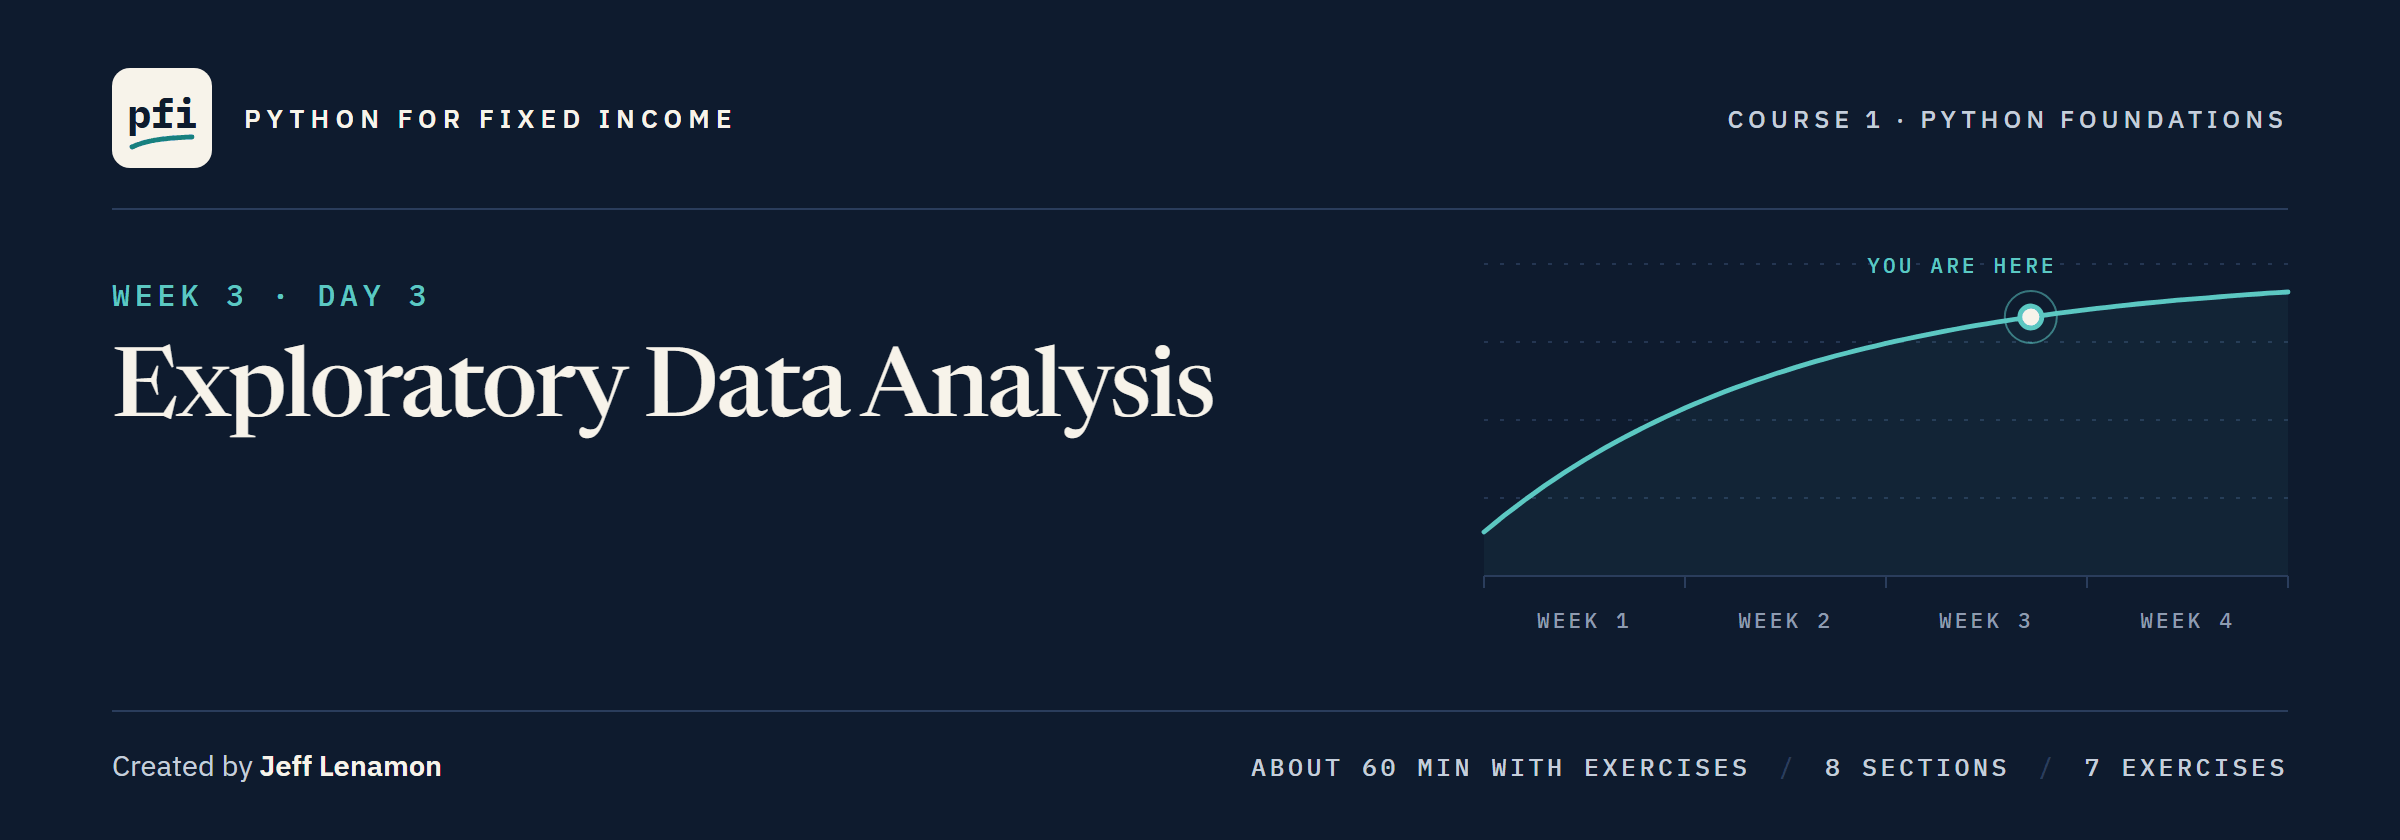

# Exploratory Data Analysis

Week 3, Day 3. A holdings file arrives with problems in it. Find them by method, decide what to do about each, and show what every decision does to the numbers.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day3/13_exploratory_data_analysis.ipynb)

## The Desk Lead's Note

> Ops sent the month-end extract, `holdings_messy.csv`, as of 2026-09-30. Their cover note says 200 bonds, 489,000,000 of face, 490,819,215 of market value. I need three numbers for the pack: market value, average OAS, average yield. Before any of them leaves the desk, tell me if the file can be trusted. Fix what you can prove, flag what you cannot, show me what each fix does to the three numbers, and give me the list for ops. Then make it run on next month's file in one line.

The issuers are invented; every statement describes the data.
Getting to know a table before relying on it is **exploratory data analysis**, or EDA.

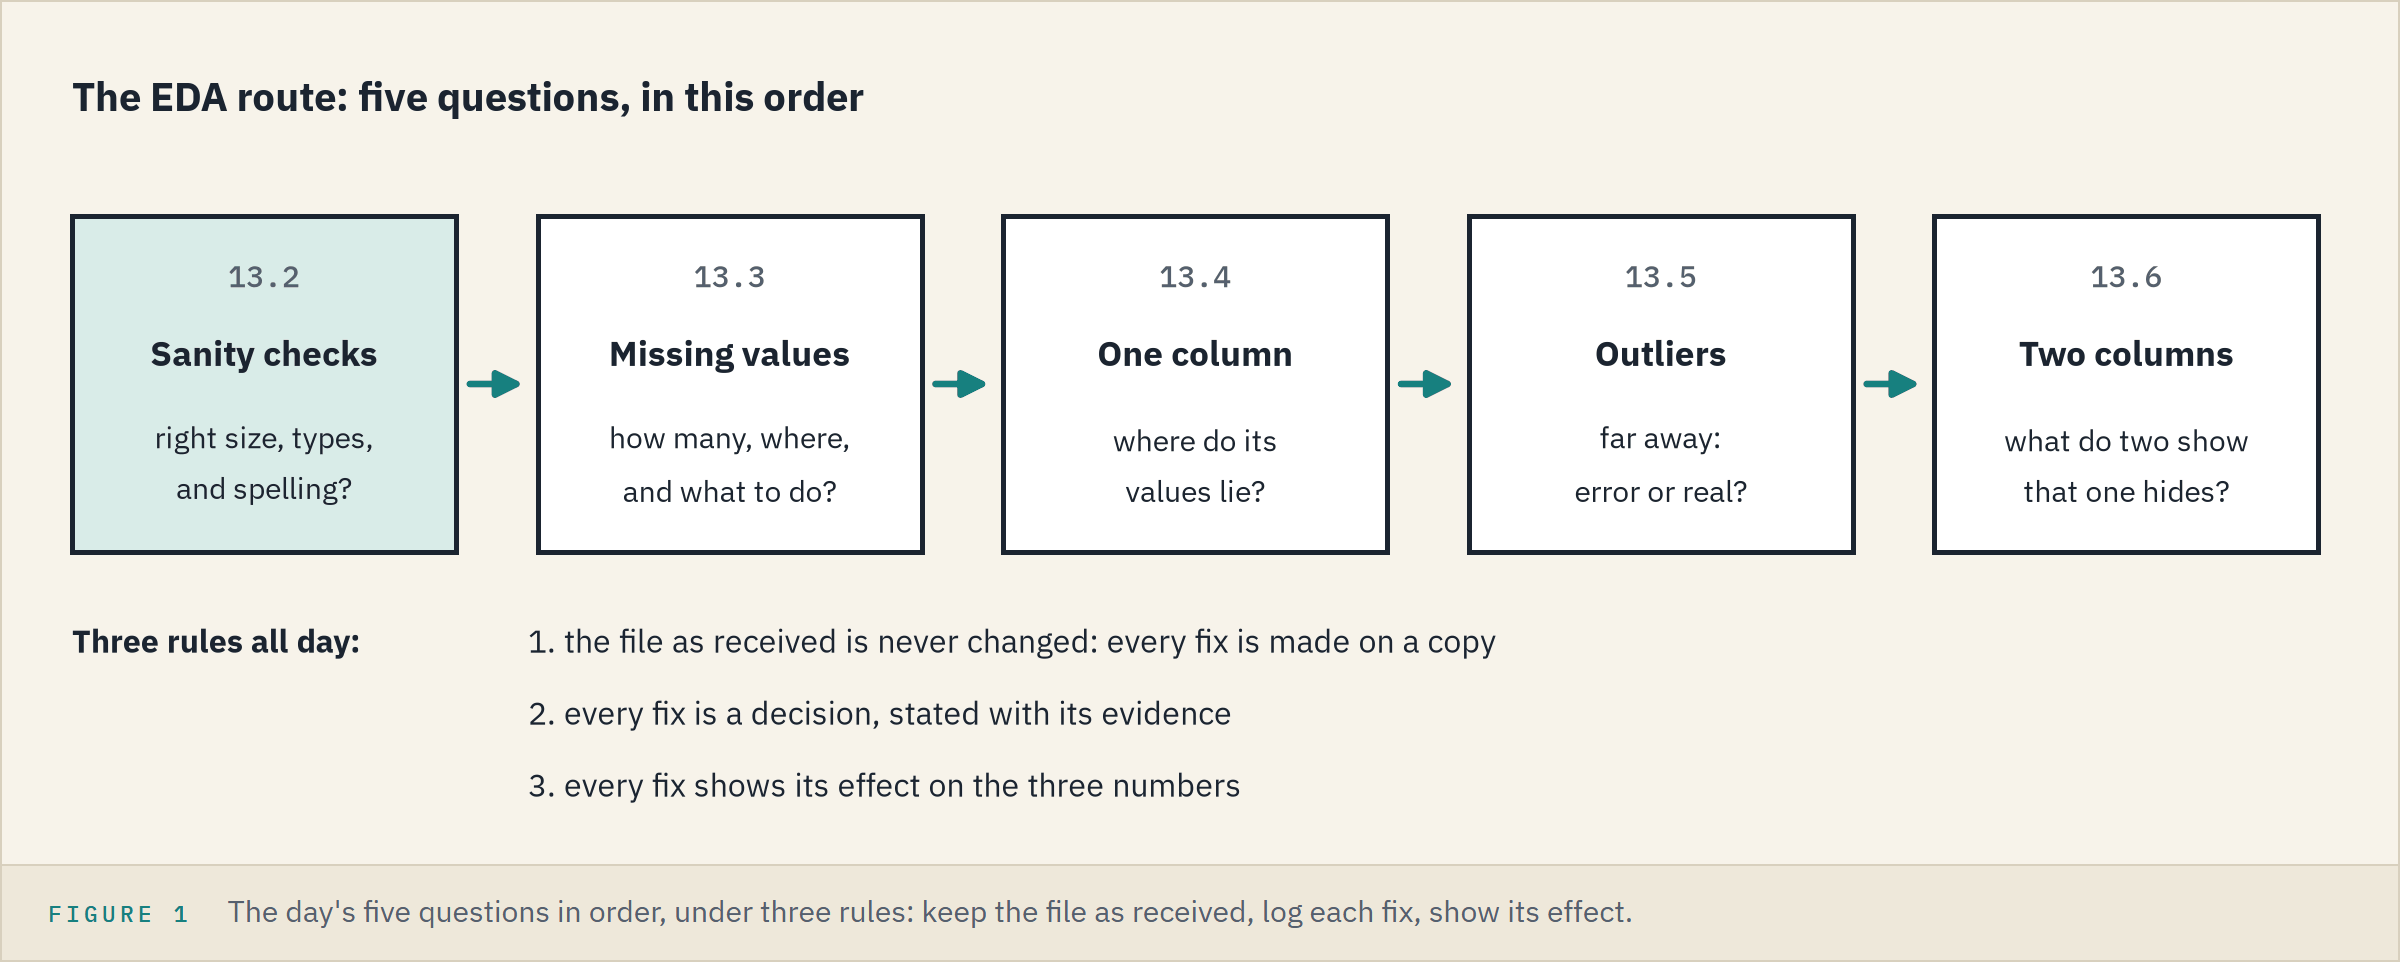

**Three numbers, one file, and nothing leaves the desk until the file adds up.**

## Your Route Through Day 3

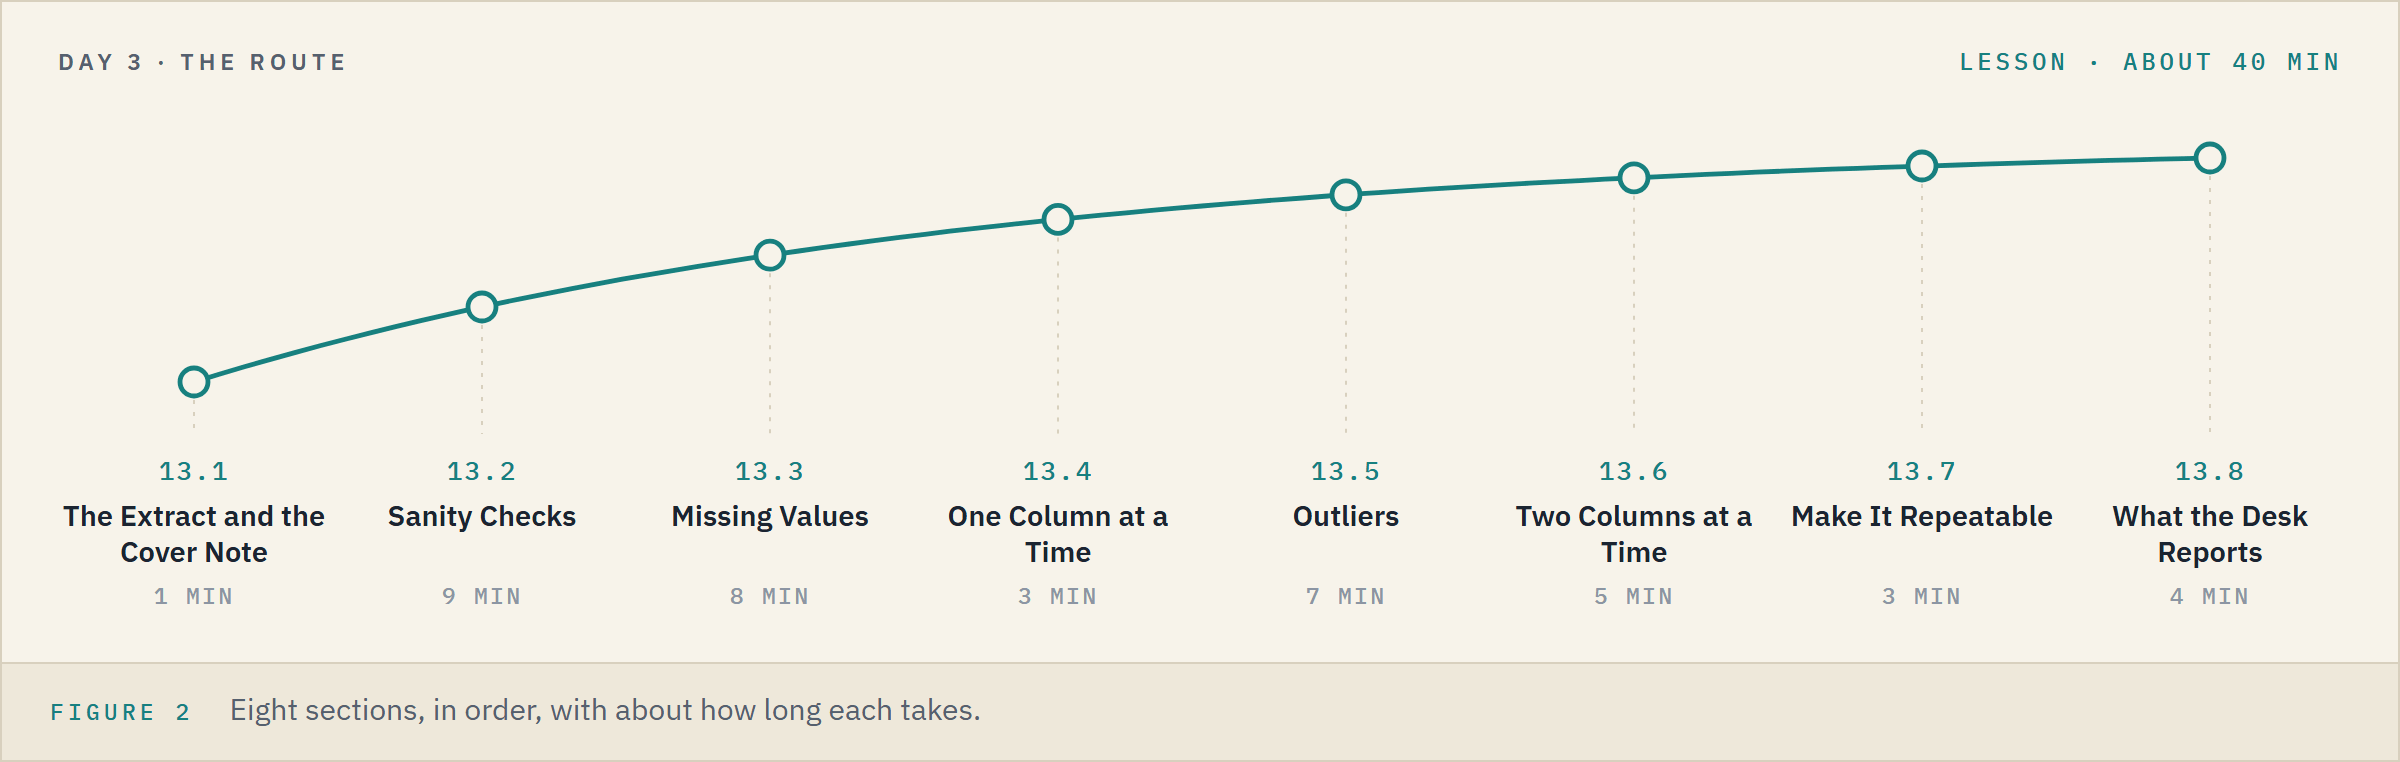

**Time.** About 40 minutes for the lesson, then about 21 for the seven exercises.

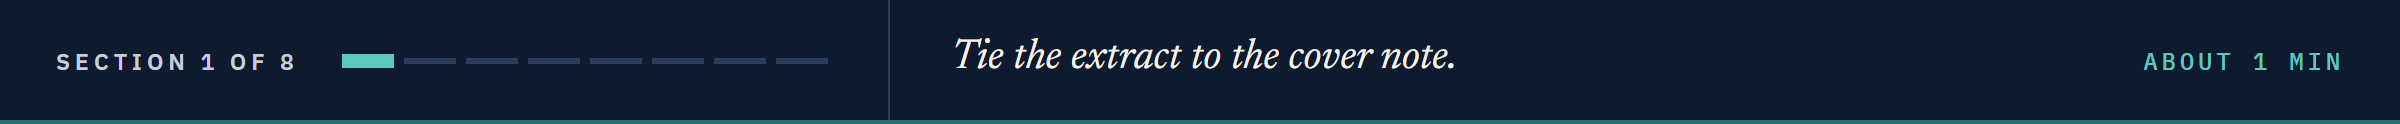

## 13.1 The Extract and the Cover Note

### Load the Extract

Q. Load the extract and the rating scale. How many rows came?

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# the house greens and greys for every chart, as in Visualization
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'],
              rc={'boxplot.medianprops.color': '#1E4D3A'})
# the repo's data folder on your machine; in Colab, GitHub, as in pandas Part 1
if os.path.exists('../../../data/holdings_messy.csv'):
    data_folder = '../../../data/'
else:
    data_folder = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/'
# raw is the file exactly as it arrived: nothing today changes it
raw = pd.read_csv(data_folder + 'holdings_messy.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
# the seven buckets in credit order, as in Visualization
bucket_order = ratings.sort_values('score')['bucket'].unique().tolist()
print(raw.shape, ratings.shape)

(204, 19) (18, 4)


### The Cover Note and the Headline

Q. Store the cover note's figures, then print the three numbers as the file stands.

In [2]:
# the cover note's control totals: bonds, face in dollars, market value in dollars
expected_bonds = 200
expected_face = 489000000
expected_value = 490819215

# rows, market value in dollars, mean OAS in bp, mean yield in percent, on one line
def headline(label, table):
    print(label, '| rows:', len(table), '| market value:', table['market_value'].sum(),
          '| OAS:', round(table['oas'].mean(), 2),
          '| yield:', round(table['yield_pct'].mean(), 3))


headline('As received', raw)

As received | rows: 204 | market value: 497769925.0 | OAS: 187.83 | yield: 6.051


**204 rows against 200: a finding before the first check.**

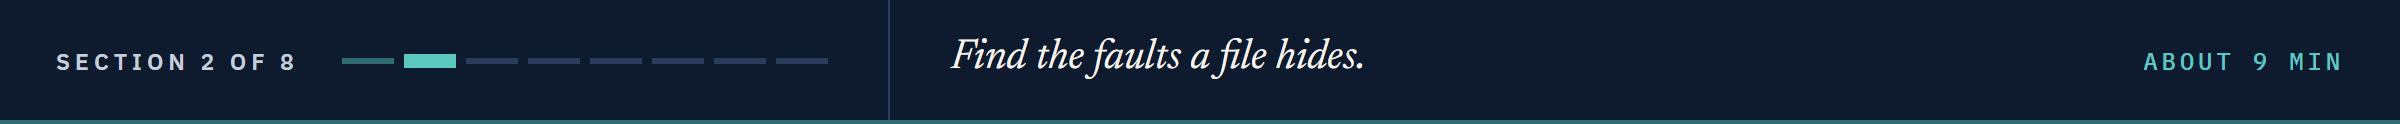

## 13.2 Sanity Checks

A sanity check asks a question whose answer you already know.

### Size and Totals

Q. How far is the file from the cover note?

In [3]:
# each figure in the file, less the cover note's
print('Rows:', len(raw) - expected_bonds)
print('Face:', raw['par_held'].sum() - expected_face)
print('Market value:', raw['market_value'].sum() - expected_value)

Rows: 4
Face: 6500000
Market value: 6950710.0


All three are over, none under: something was added.

### Dates Held as Text

Q. How many days separate the oldest price from the newest?

In [4]:
# the newest price date less the oldest
raw['price_date'].max() - raw['price_date'].min()

TypeError: unsupported operand type(s) for -: 'str' and 'str'

`max()` ran, because text sorts; the minus failed: the dates arrived as text, as in Combining Part 2.
Older pandas, as in Colab, calls a text column `object`, not `str`.

Q. Convert the three dates in a working copy, count any that fail, and try again.

In [5]:
# book is the working copy, as with pandas Part 2's .copy(): raw stays as it arrived
book = raw.copy()
# format= names the layout: %Y a four-digit year, %m the month, %d the day
# errors='coerce' turns text that does not fit the layout into a missing date
for column in ['as_of_date', 'maturity', 'price_date']:
    book[column] = pd.to_datetime(book[column], format='%Y-%m-%d', errors='coerce')
    print(column, 'not read:', book[column].isna().sum())
print('Prices from', book['price_date'].min(), 'to', book['price_date'].max())
print('As-of dates:', book['as_of_date'].nunique())

as_of_date not read: 0
maturity not read: 0
price_date not read: 0
Prices from 2026-08-04 00:00:00 to 2026-09-30 00:00:00
As-of dates: 1


Every date read; always print that count, because a coerce turns a bad date into a silent gap.
One as-of date, yet the prices span 57 days: hold that thought.

### Numbers That Arrive as Text

Q. Another system writes `missing` and `--` in its price column. What does pandas make of it?

In [6]:
import io

# a four-bond file in a cell, read with io.StringIO, as in Combining Part 2; \n ends a line
csv_text = 'cusip,price\n00000AA01,100.5\n00000AA02,missing\n00000AA03,98.25\n00000AA04,--\n'
prices = pd.read_csv(io.StringIO(csv_text))['price']
# to_numeric() turns text into numbers; errors='coerce' makes the rest missing, so count them
print(prices.dtype, '| not numbers:', pd.to_numeric(prices, errors='coerce').isna().sum())
# na_values= names the words to read as missing, so the column arrives as numbers
print(pd.read_csv(io.StringIO(csv_text), na_values=['missing', '--'])['price'].dtype)

str | not numbers: 2
float64


`NA` and an empty cell are missing already; `na_values=` adds a system's own words.

### Rows Sent Twice

Q. Does any row repeat an earlier one, and what do the copies carry?

In [7]:
# duplicated(), as in the First Look case study: each repeat of an earlier row or CUSIP
print('Rows:', book.duplicated().sum(), '| CUSIPs:', book['cusip'].duplicated().sum())
# keep=False marks the first appearance too
print('Rows marked with keep=False:', book.duplicated(keep=False).sum())
copies = book[book.duplicated()]
print('Copies at rows:', copies.index.tolist())
print('Face:', copies['par_held'].sum(), '| market value:', copies['market_value'].sum())

Rows: 4 | CUSIPs: 4
Rows marked with keep=False: 8
Copies at rows: [200, 201, 202, 203]
Face: 6500000 | market value: 6950710.0


Four rows and four CUSIPs, so no CUSIP comes back with other values.
The copies sit at the end of the file and carry the cover note's two gaps to the dollar.

### Decision 1: Remove the Copies

In [8]:
# drop_duplicates() keeps each first appearance; reset_index(drop=True) numbers rows 0 to 199
book = book.drop_duplicates().reset_index(drop=True)
headline('Decision 1', book)
print('Off the note:', len(book) - expected_bonds, book['par_held'].sum() - expected_face,
      book['market_value'].sum() - expected_value, '| raw still has', len(raw), 'rows')

Decision 1 | rows: 200 | market value: 490819215.0 | OAS: 185.75 | yield: 6.028
Off the note: 0 0 0.0 | raw still has 204 rows


**Both totals tie to the dollar: the four copies were the whole gap.**

### Names and Tickers

Q. Are the CUSIPs nine characters, and does each issuer have one ticker?

In [9]:
# .str applies a text method to every value; .str.len() counts the characters
print('CUSIP lengths:', book['cusip'].str.len().value_counts().to_dict())
print('Issuers:', book['issuer'].nunique(), '| tickers:', book['ticker'].nunique())
# strip() and upper(), as on week 1's Day 1; tolist() shows each value in quotes, spaces too
tidy = book['ticker'].str.strip().str.upper()
untidy = book['ticker'] != tidy
print('Untidy:', untidy.sum(), book.loc[untidy, 'ticker'].tolist())

CUSIP lengths: {9: 200}
Issuers: 115 | tickers: 121
Untidy: 8 ['cora', 'CORX ', 'dran', ' elvl ', ' FESH', ' thaa ', 'WYXR ', ' XANE']


All 200 CUSIPs have nine characters, but 115 issuers carry 121 tickers, and eight tickers are untidy.
DRAN and ELVL are single-bond issuers, so a count of tickers per issuer would have missed them; the column test does not.

### Decision 2: Tidy the Tickers

Q. What does tidying do to THAA's market value?

In [10]:
# THAA's market value grouped as received, then the fix, then grouped again
print('THAA as received:', book.groupby('ticker')['market_value'].sum()['THAA'])
book['ticker'] = tidy
print('THAA tidied:', book.groupby('ticker')['market_value'].sum()['THAA'])
print('Tickers:', book['ticker'].nunique(), '| issuers:', book['issuer'].nunique())
headline('Decision 2', book)

THAA as received: 2659800.0
THAA tidied: 4517617.5
Tickers: 115 | issuers: 115
Decision 2 | rows: 200 | market value: 490819215.0 | OAS: 185.75 | yield: 6.028


As received, THAA was short 1,857,817.5, and nothing warned.
One ticker per issuer is the evidence for the fix.
The headline does not move: a fix can matter to one report and not to another.

### Spellings and the Rating Scale

Q. Are the sectors spelled one way, and is every rating on the scale?

In [11]:
# the ticker test with .str.title(), a capital at the start of each word
untidy_sectors = book['sector'] != book['sector'].str.strip().str.title()
print('Sectors:', book['sector'].nunique(), '| untidy:', untidy_sectors.sum())
# isin() tests each rating against the scale; dropna=False keeps the gaps in a count
known = book['rating'].isin(ratings['rating'])
off_scale = book.loc[~known, 'rating'].value_counts(dropna=False)
print('On the scale:', known.sum(), '| off it:', off_scale.to_dict())

Sectors: 10 | untidy: 0
On the scale: 195 | off it: {nan: 5}


Five ratings are missing, not misspelled: 13.3 takes them up.

### Values That Cannot Be Right

Q. Does any value break a rule no bond can break?

In [12]:
# each count should be 0
not_positive = (book[['price', 'coupon', 'duration']] <= 0).sum().sum()
print('Price, coupon, or duration at or below 0:', not_positive)
print('Matured:', (book['maturity'] <= book['as_of_date']).sum())
print('Face above outstanding:', (book['par_held'] > book['amount_outstanding']).sum())
# market value rebuilt from face, price, and accrued, per 100 of face; abs() drops the sign
worked_out = book['par_held'] * (book['price'] + book['accrued']) / 100
print('Largest market value gap:', round((worked_out - book['market_value']).abs().max(), 2))

Price, coupon, or duration at or below 0: 0
Matured: 0
Face above outstanding: 0
Largest market value gap: 0.0


No bond breaks a rule, and market value rebuilds to the cent.

### Decision 3: Flag the August Prices

Q. Which prices are dated before the as-of date?

In [13]:
# a price dated before the as-of date is stale
stale = book[book['price_date'] < book['as_of_date']]
days_old = (stale['as_of_date'] - stale['price_date']).dt.days
print(len(stale), 'bonds,', days_old.min(), 'to', days_old.max(), 'days old')
share = stale['market_value'].sum() / book['market_value'].sum() * 100
print('Market value:', stale['market_value'].sum(), '|', round(share, 2), 'percent')

6 bonds, 35 to 57 days old
Market value: 13342347.5 | 2.72 percent


Decision 3: flag the six for ops and change nothing.
The right price is not in the file, and an invented price is worse than an old one.

**Excel side by side.** Price in I, price date in J, market value in S:

<table align="left">
<tr><th align="left">Check</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Rows and totals</td><td align="left"><code>len(raw)</code>, <code>.sum()</code></td><td align="left"><code>=COUNTA(B2:B205)</code>, <code>=SUM(S2:S205)</code></td></tr>
<tr><td align="left">Number or text</td><td align="left"><code>dtypes</code></td><td align="left"><code>=ISNUMBER(I2)</code>, <code>=ISTEXT(I2)</code></td></tr>
<tr><td align="left">Words for missing</td><td align="left"><code>na_values=</code></td><td align="left">Power Query, Replace Values with <code>null</code></td></tr>
<tr><td align="left">Rows sent twice</td><td align="left"><code>duplicated()</code></td><td align="left"><code>=COUNTIF(B:B, B2)&gt;1</code>; Remove Duplicates deletes in place</td></tr>
<tr><td align="left">Untidy text</td><td align="left"><code>.str.strip().str.upper()</code></td><td align="left"><code>=UPPER(TRIM(C2))</code></td></tr>
<tr><td align="left">On the scale</td><td align="left"><code>isin()</code></td><td align="left"><code>=COUNTIF(ratings!A:A, F2)&gt;0</code>; Data Validation, List</td></tr>
<tr><td align="left">Stale prices</td><td align="left"><code>price_date &lt; as_of_date</code></td><td align="left"><code>=COUNTIF(J:J, "&lt;"&amp;DATE(2026, 9, 30))</code></td></tr>
</table>
<br clear="left">

Excel's `=` ignores case, so `="thaa"="THAA"` is TRUE; `EXACT` tells them apart.


**Two fixes the file proves, one flag it cannot settle. Next, what is not there.**

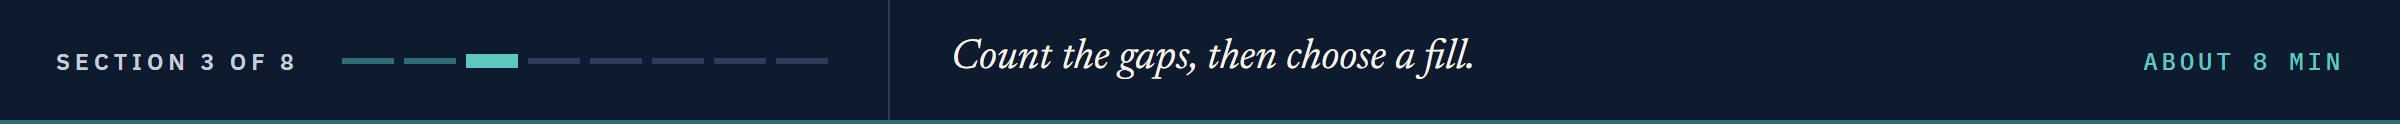

## 13.3 Missing Values

Ask three things of every gap: how many, where, and what to do.

### Five Bonds With No Rating

Q. Where are the gaps, and what happens when the scale comes in?

In [14]:
# isna().sum(), as in the First Look case study: only the columns with a gap
gaps = book.isna().sum()
print('Gaps:', gaps[gaps > 0].to_dict())
# a left merge keeps every bond, as in Combining Part 1
book = pd.merge(book, ratings, on='rating', how='left')
print('After the scale:', book[['score', 'bucket', 'grade']].isna().sum().to_dict())
# count() is the values present, len() the rows; mean() divides by count()
print(book['score'].count(), 'of', len(book), '| mean:', round(book['score'].mean(), 2))
unrated = book[book['rating'].isna()]
unrated[['ticker', 'sector', 'oas', 'market_value']]

Gaps: {'rating': 5}
After the scale: {'score': 5, 'bucket': 5, 'grade': 5}
195 of 200 | mean: 9.35


,ticker,sector,oas,market_value
26,CORL,Materials,56,4650820.0
70,GALX,Materials,350,4881337.5
105,MORX,Telecom,273,1529605.0
109,NEVE,Industrials,113,807900.0
150,SYLX,Transportation,59,3472875.0


Five bonds in four sectors, OAS from 56 to 350 bp: no cluster, which would itself be a finding.
The merge turned one gap into four, and the mean score of 9.35 is over 195 bonds: `mean()` skips a gap, as pandas Part 1's `sum()` did.

### Market Value by Grade

**Predict 1**

Q. The next cell adds up market value by grade, then adds the grades together. What comes back?

A) 490,819,215, the book.
B) Less than the book.
C) An error: five grades are missing.

In [15]:
# market value of each grade, then the grades added together
by_grade = book.groupby('grade')['market_value'].sum()
print(by_grade.to_dict())
print('Sum of the grades:', by_grade.sum(), '| book:', book['market_value'].sum())

{'High Yield': 163490907.5, 'Investment Grade': 311985770.0}
Sum of the grades: 475476677.5 | book: 490819215.0


B: 475,476,677.5, short by the five unrated bonds, with no error.
`groupby()` leaves out any row whose group is missing, and says nothing.

### Drop Them, or Guess

In [16]:
# dropna(subset=) drops a row only when a named column is missing
headline('Dropped', book.dropna(subset=['rating']))
# mode() is the most common value, as in pandas Part 2: a tie gives two
print(book['rating'].mode().tolist())
# fillna() puts a value in every gap: here one of the two, BBB-, then the scale again
guessed = pd.merge(book[['rating']].fillna('BBB-'), ratings, on='rating')
print(guessed['grade'].value_counts().to_dict())

Dropped | rows: 195 | market value: 475476677.5 | OAS: 186.15 | yield: 6.03
['A-', 'BBB-']
{'Investment Grade': 130, 'High Yield': 70}


Dropping takes real bonds out, and every number moves; a bare `dropna()` would drop a gap in any column.
The guess is a tie, so a choice: five bonds become investment grade on ratings nobody gave them.

### Decision 4: Fill With a Label

In [17]:
# the bucket and grade of the five become 'Not rated'; rating and score stay missing
book['bucket'] = book['bucket'].fillna('Not rated')
book['grade'] = book['grade'].fillna('Not rated')
# the label joins the end of the credit order
bucket_order = bucket_order + ['Not rated']
headline('Decision 4', book)
print(book.groupby('grade')['market_value'].sum().to_dict())

Decision 4 | rows: 200 | market value: 490819215.0 | OAS: 185.75 | yield: 6.028
{'High Yield': 163490907.5, 'Investment Grade': 311985770.0, 'Not rated': 15342537.5}


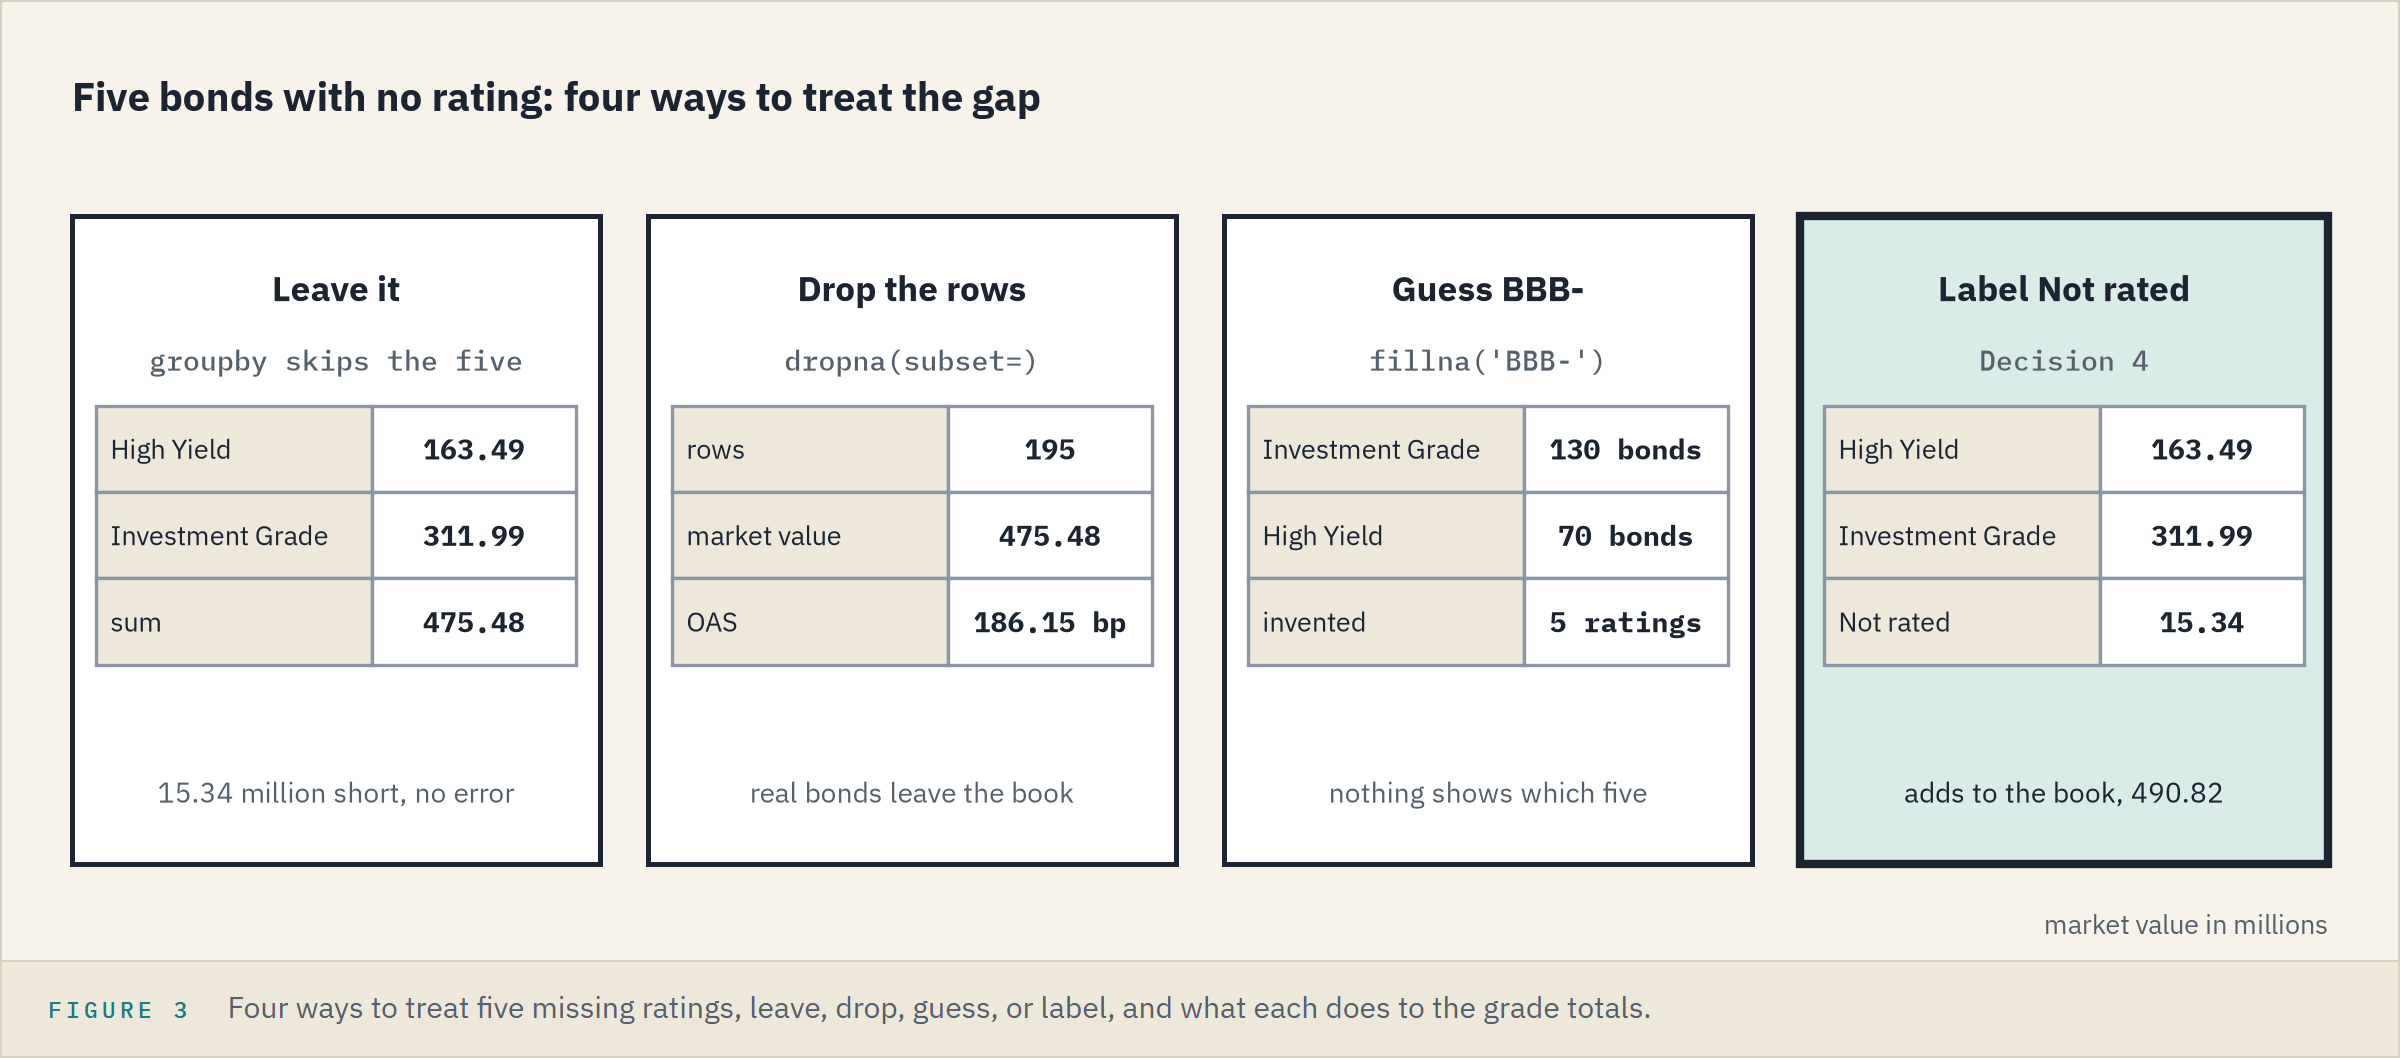

Try each treatment on a copy, print what it does, and write the choice down.
A column more than half empty is usually dropped whole, with `drop(columns=)`.

### Fill a Number From Its Group

Q. Blank eight OAS values in a copy: which fills them closer, the column's median or each bucket's?

In [18]:
# sample() picks 8 rows at random; random_state= picks the same 8 every run
test = book.copy()
blanked = test.sample(8, random_state=1).index
# np.nan is NumPy's missing value, the NaN pandas shows for a gap
test.loc[blanked, 'oas'] = np.nan
buckets = test.loc[blanked, 'bucket']
print('Blanked:', test['oas'].isna().sum(), '| their buckets:', buckets.tolist())

Blanked: 8 | their buckets: ['BB', 'AAA', 'BB', 'BB', 'B', 'A', 'BBB', 'BBB']


In [19]:
# transform('median') hands every row its own bucket's median, lined up for fillna()
column_fill = test['oas'].fillna(test['oas'].median())
bucket_fill = test['oas'].fillna(test.groupby('bucket')['oas'].transform('median'))
# the miss: each fill less the true OAS in book, sign dropped, averaged over the eight
miss_by_column = (column_fill - book['oas'])[blanked].abs().mean()
miss_by_bucket = (bucket_fill - book['oas'])[blanked].abs().mean()
print('Average miss, column median:', round(miss_by_column, 1), 'bp')
print('Average miss, bucket median:', round(miss_by_bucket, 1), 'bp')

Average miss, column median: 63.6 bp
Average miss, bucket median: 47.1 bp


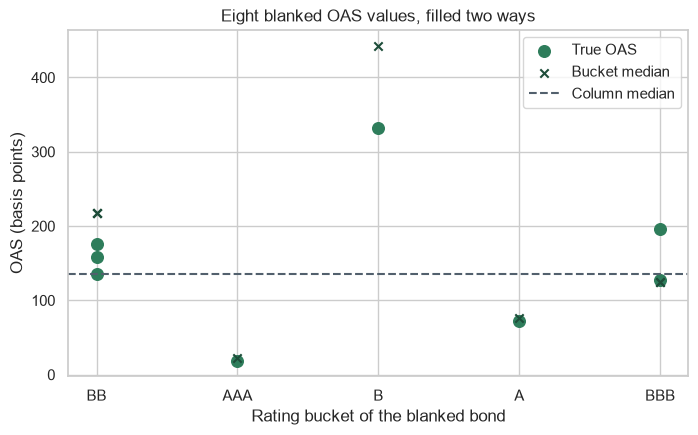

In [20]:
# the eight true values against the two fills
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(buckets, book.loc[blanked, 'oas'], s=70, label='True OAS')
ax.scatter(buckets, bucket_fill[blanked], marker='x', color='#1E4D3A', label='Bucket median')
ax.axhline(test['oas'].median(), color='#52606D', linestyle='--', label='Column median')
ax.legend()
ax.set_title('Eight blanked OAS values, filled two ways')
ax.set_xlabel('Rating bucket of the blanked bond')
ax.set_ylabel('OAS (basis points)')
plt.show()

The column median hands all eight the same 135; the bucket median follows the rating.

### A Hundred Draws

Q. One draw can be luck. Does the bucket fill win over 100?

In [21]:
# the same test with 100 random picks; np.mean() averages each list, as in NumPy Part 1
def average_miss(column):
    column_miss, bucket_miss = [], []
    for seed in range(100):
        test = book.copy()
        blanked = test.sample(8, random_state=seed).index
        test.loc[blanked, column] = np.nan
        by_column = test[column].fillna(test[column].median())
        by_bucket = test[column].fillna(test.groupby('bucket')[column].transform('median'))
        column_miss.append((by_column - book[column])[blanked].abs().mean())
        bucket_miss.append((by_bucket - book[column])[blanked].abs().mean())
    print(column, '| column median:', round(np.mean(column_miss), 2),
          '| bucket median:', round(np.mean(bucket_miss), 2))


average_miss('oas')

oas | column median: 102.57 | bucket median: 55.37


On OAS the bucket median misses by about half as much: a rating says a lot about a spread.

### The Same Test on Duration

**Predict 2**

Q. Over the same 100 draws, how does the bucket median do on duration?

A) Clearly better than the column median.
B) About level with it.
C) Clearly worse.

In [22]:
# the same function, another column
average_miss('duration')

duration | column median: 2.58 | bucket median: 2.65


B: a rating says almost nothing about how long a bond runs.
A group fill is only as good as its grouping, so test it first; no fill is a measurement.

**Excel side by side.** Rating in F, market value in S:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Count gaps</td><td align="left"><code>isna().sum()</code></td><td align="left"><code>=COUNTBLANK(F2:F201)</code></td></tr>
<tr><td align="left">Value with no rating</td><td align="left"><code>.sum()</code> on the five</td><td align="left"><code>=SUMIF(F2:F201, "", S2:S201)</code></td></tr>
<tr><td align="left">Skip gaps</td><td align="left"><code>mean()</code></td><td align="left"><code>AVERAGE</code> skips blanks; <code>=AGGREGATE(1, 6, ...)</code> skips <code>#N/A</code> too</td></tr>
<tr><td align="left">Fill every gap</td><td align="left"><code>fillna()</code></td><td align="left">Go To Special, Blanks, type, Ctrl+Enter</td></tr>
</table>
<br clear="left">

**Text gets an honest label; a number gets its group's median, tested first. Now the values themselves.**

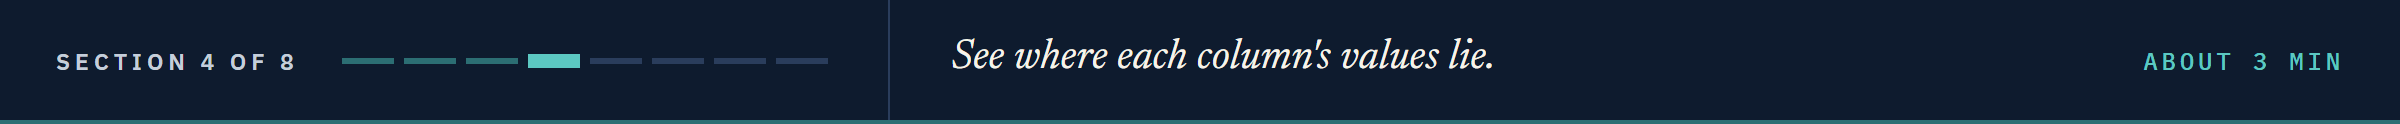

## 13.4 One Column at a Time

Looking at one column on its own is **univariate** analysis.

### The Yields as a Histogram

Q. Where do the yields lie?

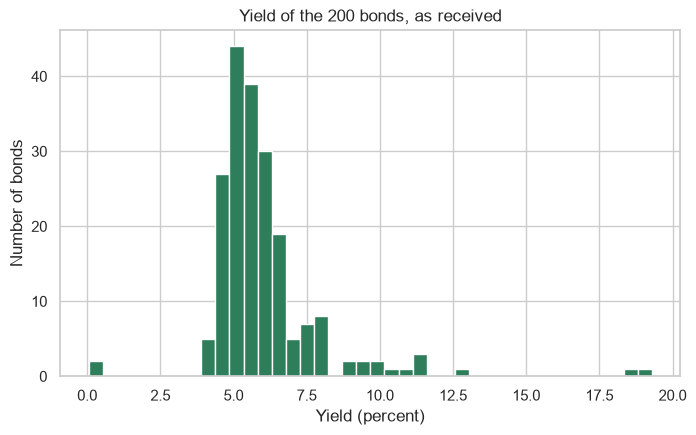

[0.04706, 0.07308, 4.089, 4.127]


In [23]:
# 40 bins of yield, then the four lowest yields
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(book['yield_pct'], bins=40)
ax.set_title('Yield of the 200 bonds, as received')
ax.set_xlabel('Yield (percent)')
ax.set_ylabel('Number of bonds')
plt.show()
print(book['yield_pct'].nsmallest(4).tolist())

Two bars stand alone near zero, four points below the next yield: the chart shows how many and how far.

### Mean, Median, and Skew

**Skew** measures how lopsided a column is: positive with a tail on the right, negative on the left, near 0 when the halves match.

In [24]:
# agg() with a list: three summaries of five columns at once
columns = ['price', 'yield_pct', 'oas', 'duration', 'dts']
book[columns].agg(['mean', 'median', 'skew']).round(2)

,price,yield_pct,oas,duration,dts
mean,98.83,6.03,185.75,6.47,1133.22
median,99.42,5.53,135.50,6.31,811.00
skew,-0.71,3.07,3.93,0.50,1.95


OAS skews 3.93, its mean 50 bp above its median; price skews left, as Visualization drew it.

### Every Column at Once

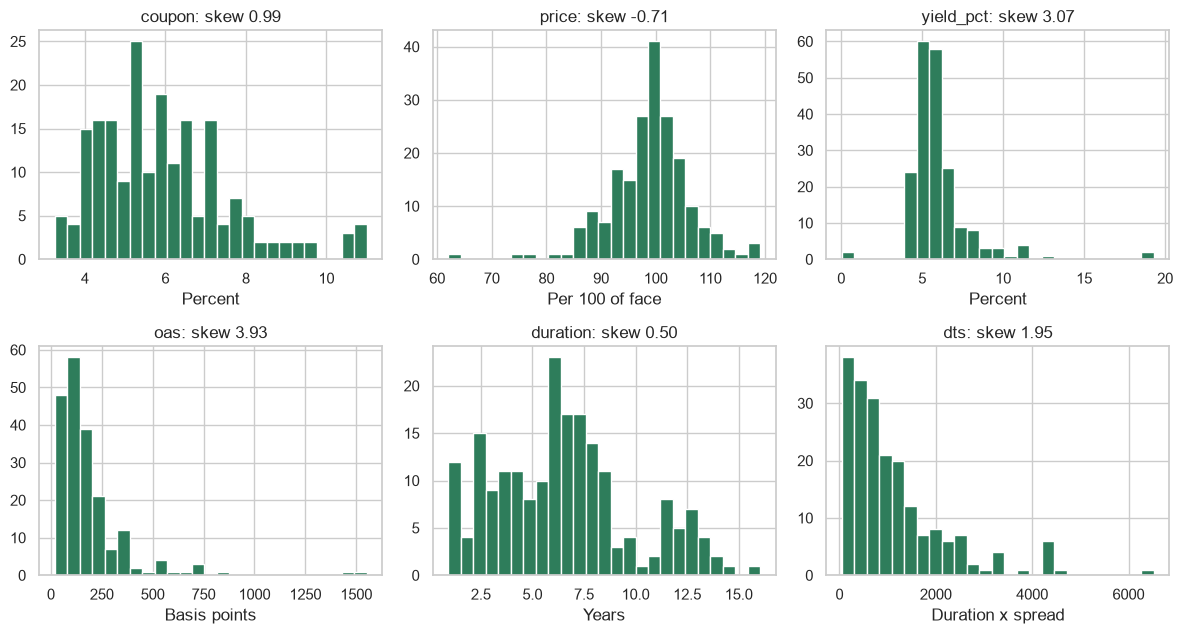

In [25]:
# six columns and the unit of each, then a 2 by 3 grid of axes, one per column
units = {'coupon': 'Percent', 'price': 'Per 100 of face', 'yield_pct': 'Percent',
         'oas': 'Basis points', 'duration': 'Years', 'dts': 'Duration x spread'}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, (column, unit) in zip(axes.flatten(), units.items()):
    ax.hist(book[column], bins=25)
    ax.set_title(f'{column}: skew {book[column].skew():.2f}')
    ax.set_xlabel(unit)
plt.tight_layout()
plt.show()

`flatten()` lines the 2 by 3 grid of axes up in one row, so `zip()` can pair each axes with a column and its unit, unpacked as in week 1's Day 1, Part 2.
Five shapes a bond book would have; only the yield panel has a gap at its far left.

**One minimum looks wrong and a few bonds stand far out. Next: error, or real.**

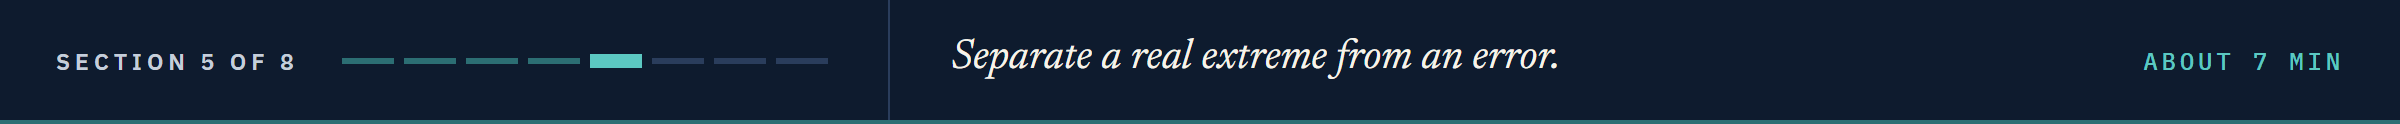

## 13.5 Outliers

An **outlier** is a value far from the rest.

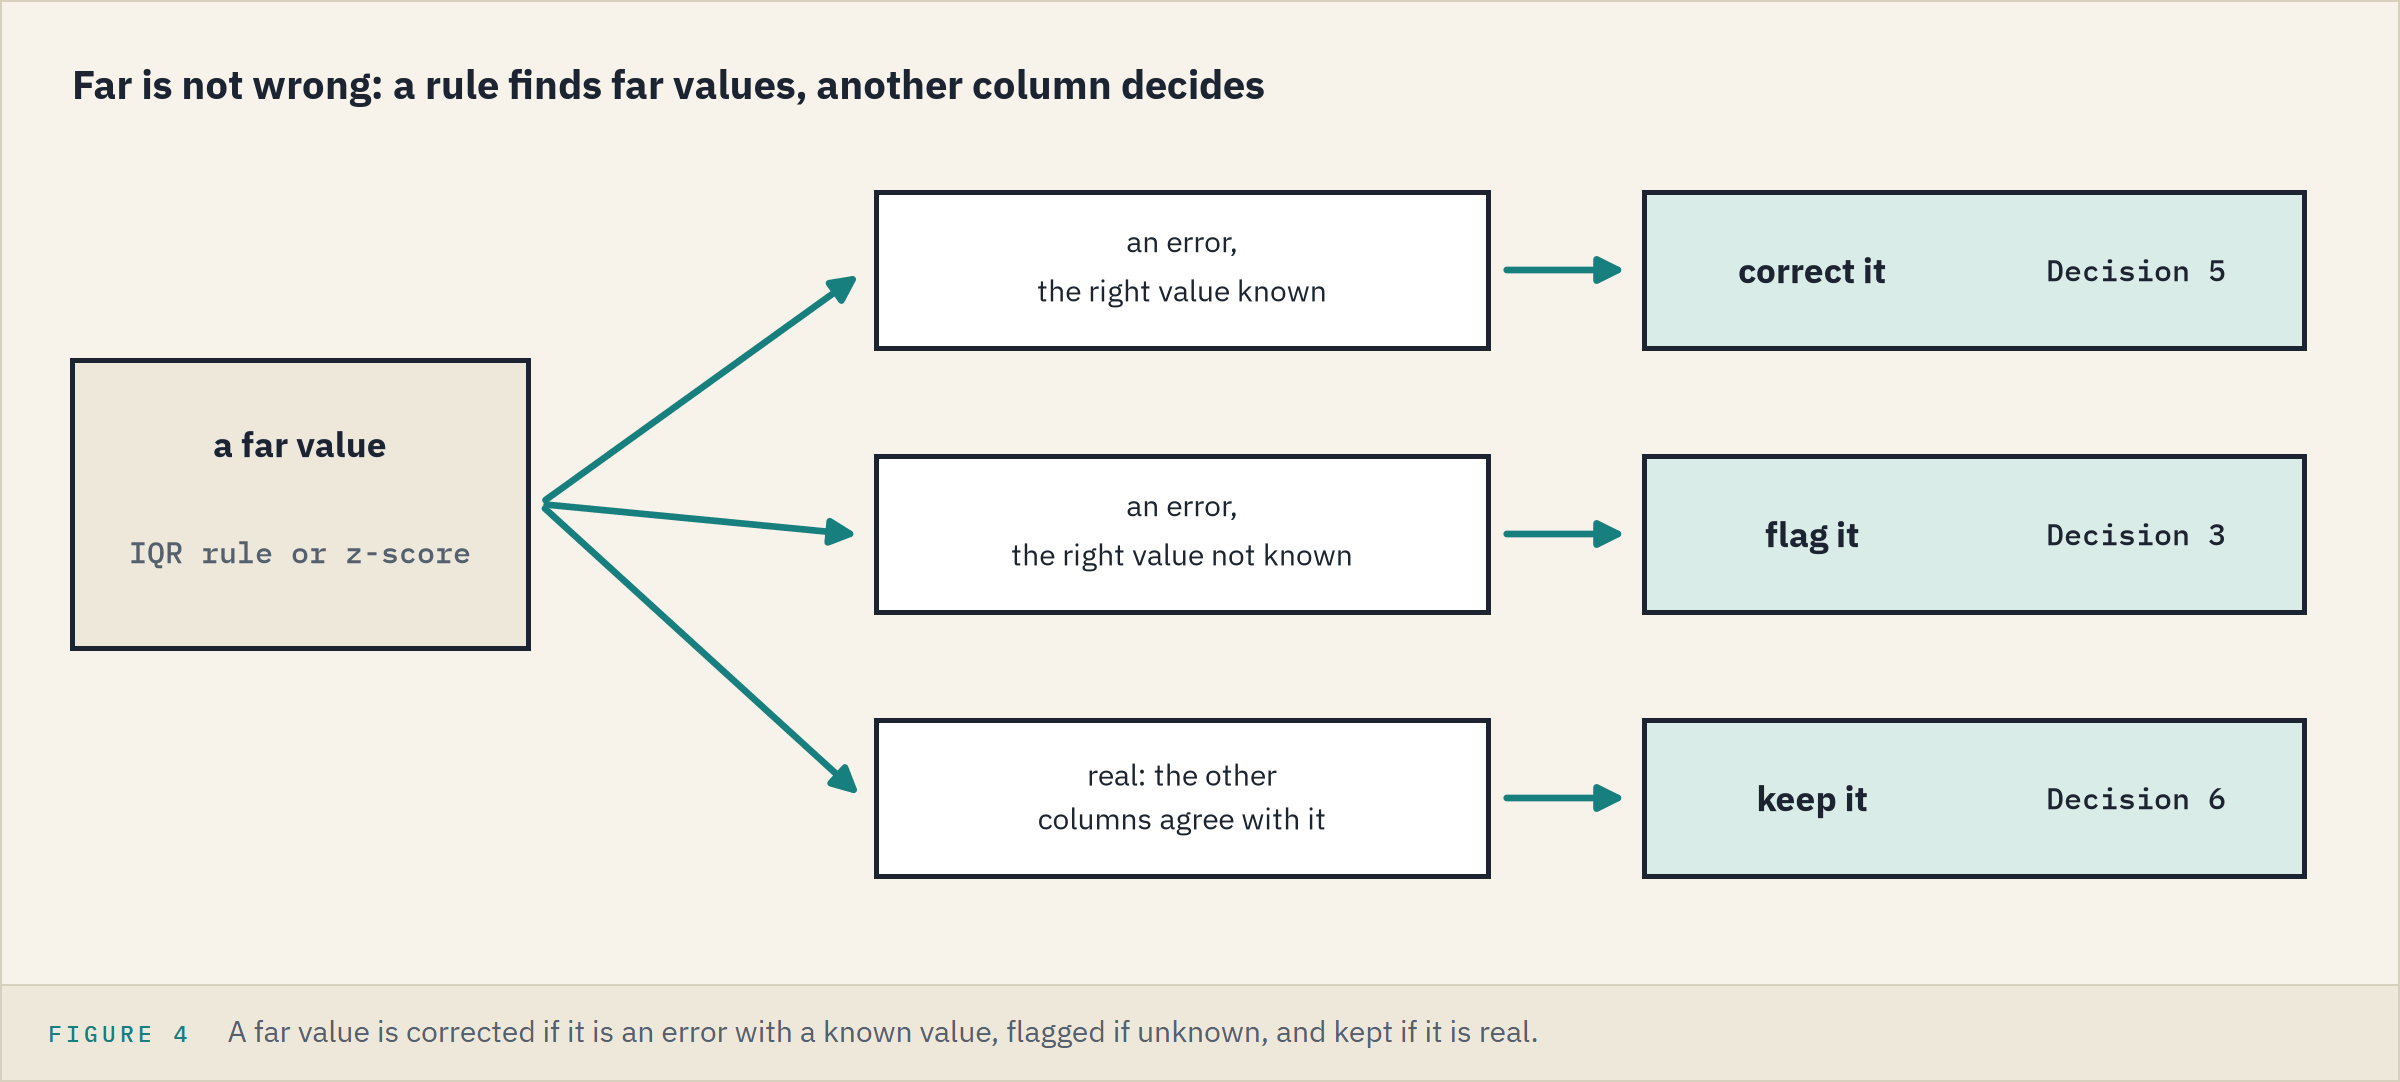

Far has two causes, an error or a real extreme, and a rule cannot tell them apart.

### The IQR Rule on the Yields

Q. Visualization's box drew any value 1.5 x IQR beyond the box as a circle. Which yields?

In [26]:
# the quartiles, the IQR, and the two limits
q1, q3 = book['yield_pct'].quantile(0.25), book['yield_pct'].quantile(0.75)
lower_limit, upper_limit = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
low_yield = book['yield_pct'] < lower_limit
high_yield = book['yield_pct'] > upper_limit
inside = ~low_yield & ~high_yield
print(round(q1, 3), round(q3, 3), '| limits:', round(lower_limit, 3), round(upper_limit, 3))
print('Below:', low_yield.sum(), '| above:', high_yield.sum(), '| inside:', inside.sum())

5.049 6.39 | limits: 3.038 8.401
Below: 2 | above: 14 | inside: 184


Sixteen bonds past the limits: Visualization's box would draw them as sixteen circles, all alike.

### The Two Lowest

Q. What else do the two lowest carry?

In [27]:
# the two flagged bonds and the columns that can confirm a yield
book.loc[low_yield, ['ticker', 'rating', 'coupon', 'price', 'yield_pct', 'oas']]

,ticker,rating,coupon,price,yield_pct,oas
123,PLEA,AA,7.25,119.131,0.04706,38
152,THAA,BB,7.00,96.623,0.07308,275


A bond below par yields more than its coupon: THAA at 96.623 should yield over 7 percent, not 0.073.

Q. Yield less spread is roughly the Treasury yield, much the same for every bond. Is it for these two, as received and times 100?

In [28]:
# yield less OAS, the OAS in basis points over 100 to make percent
base = book['yield_pct'] - book['oas'] / 100
print('The two:', base[low_yield].round(3).tolist())
others = base[~low_yield]
print('The other 198:', round(others.min(), 3), 'to', round(others.max(), 3))
# the two yields read as percent, then the same test
times_100 = book.loc[low_yield, 'yield_pct'] * 100 - book.loc[low_yield, 'oas'] / 100
print('The two, times 100:', times_100.round(3).tolist())

The two: [-0.333, -2.677]
The other 198: 3.691 to 4.585
The two, times 100: [4.326, 4.558]


Times 100, both land inside the other 198's range: entered as decimals, with the right value known.

### Decision 5: Times 100

**Predict 3**

Q. The next cell multiplies the two yields by 100. What happens to the mean and the median yield?

A) Both rise by about the same.
B) The mean rises about 0.06, the median much less.
C) The mean rises about 0.6, the median not at all.

In [29]:
# keep the column as received for later, then fix the two
received_yield = book['yield_pct'].copy()
book.loc[low_yield, 'yield_pct'] = (book.loc[low_yield, 'yield_pct'] * 100).round(3)
headline('Decision 5', book)
print('Mean moved:', round(book['yield_pct'].mean() - received_yield.mean(), 4),
      '| median moved:', round(book['yield_pct'].median() - received_yield.median(), 4))

Decision 5 | rows: 200 | market value: 490819215.0 | OAS: 185.75 | yield: 6.088
Mean moved: 0.0595 | median moved: 0.0135


B: the mean took the full size of the two errors, 11.9 points of yield spread over 200 bonds.
The median moved only because 7.308 crossed the middle, shifting it one bond.

### The Fourteen Highest

Q. Are the fourteen above the upper limit errors too?

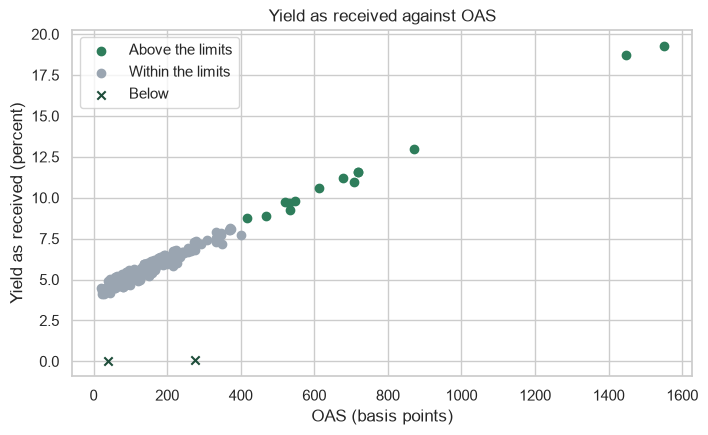

In [30]:
# yield as received against OAS: the theme colours each group in turn, green, grey, dark green
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(book.loc[high_yield, 'oas'], received_yield[high_yield], label='Above the limits')
ax.scatter(book.loc[inside, 'oas'], received_yield[inside], label='Within the limits')
ax.scatter(book.loc[low_yield, 'oas'], received_yield[low_yield], marker='x', label='Below')
ax.legend()
ax.set_title('Yield as received against OAS')
ax.set_xlabel('OAS (basis points)')
ax.set_ylabel('Yield as received (percent)')
plt.show()

The fourteen sit on the line the other 184 draw; the two crosses sit far off it.
**An error breaks a relationship; a real extreme keeps it.**

### Another Way to Say Far

A **z-score** is a value's distance from the mean in standard deviations: (value - mean) / std.

In [31]:
# std() divides by n minus 1, as Excel's STDEV.S does
z = (book['oas'] - book['oas'].mean()) / book['oas'].std()
print('Std:', round(book['oas'].std(), 2), '| top z:', round(z.max(), 2))
print('Above 3:', (z > 3).sum(), '| above 2:', (z > 2).sum())
print('OAS above 3:', book.loc[z > 3, 'oas'].tolist())
# Visualization's IQR limit for OAS, 409.875 bp, beside the fourteen high yields
wide = book['oas'] > 409.875
print('Past 409.875:', wide.sum(), '| same as the high yields:', (wide == high_yield).all())
print('Their ratings:', sorted(book.loc[wide, 'rating'].unique()))

Std: 193.95 | top z: 7.04
Above 3: 3 | above 2: 8
OAS above 3: [1446, 1551, 871]
Past 409.875: 14 | same as the high yields: True
Their ratings: ['B', 'B+', 'B-', 'CCC', 'CCC+']


The fourteen high yields are the book's fourteen widest spreads, all rated B+ or lower: real high yield bonds.
The z-score flags 3 where the IQR rule flags 14, because the extremes inflate the standard deviation they are measured by.
Neither rule proves a column clean: a wrong value can sit inside the box.

### Delete the Fourteen

**Predict 4**

Q. The mean OAS is 185.75 bp. Take out the 14 bonds past 409.875 bp: what is the mean OAS of the rest? Write down a number.

In [32]:
# a separate table without the 14: book is not changed
trimmed = book[~wide]
headline('Without the 14', trimmed)
print('Median OAS:', trimmed['oas'].median())
print('Market value removed:', book.loc[wide, 'market_value'].sum())
# or cap: clip(upper=) pulls every value above the limit down to it
capped = book['oas'].clip(upper=409.875)
print('Capped:', (capped != book['oas']).sum(), '| mean:', round(capped.mean(), 2),
      '| median:', capped.median())

Without the 14 | rows: 186 | market value: 459945087.5 | OAS: 144.21 | yield: 5.67
Median OAS: 125.5
Market value removed: 30874127.5
Capped: 14 | mean: 162.81 | median: 135.5


144.21: the mean falls by about a fifth of itself, and now describes a book the desk does not own.
Capping keeps the rows and invents their values: fine for a model, on a copy, never for the book of record.

### Decision 6: Keep Them

The fourteen are real bonds, and they stay.

**Excel side by side.** Yield in L, OAS in M:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Skew</td><td align="left"><code>skew()</code></td><td align="left"><code>=SKEW(M2:M201)</code></td></tr>
<tr><td align="left">Quartiles</td><td align="left"><code>quantile(0.25)</code></td><td align="left"><code>=QUARTILE.INC(L2:L201, 1)</code></td></tr>
<tr><td align="left">z-score</td><td align="left"><code>(x - mean) / std</code></td><td align="left"><code>=STANDARDIZE(M2, AVERAGE(M$2:M$201), STDEV.S(M$2:M$201))</code></td></tr>
<tr><td align="left">Cap</td><td align="left"><code>clip(upper=409.875)</code></td><td align="left"><code>=MIN(M2, 409.875)</code></td></tr>
</table>
<br clear="left">

**A row is never deleted because it is far away.**

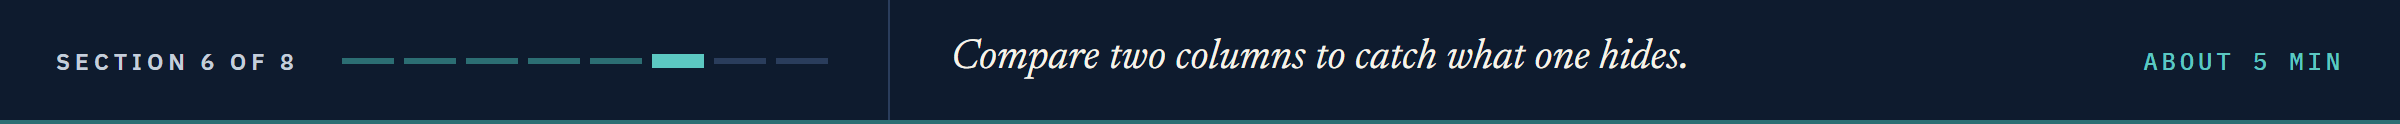

## 13.6 Two Columns at a Time

Two columns together is **bivariate** analysis.

### One Number, Two Grades

Q. What did the two errors do to yield and OAS, and does yield move with duration?

In [33]:
# yield and OAS before and after Decision 5
print('Yield and OAS, as received:', round(received_yield.corr(book['oas']), 2))
print('Yield and OAS, corrected:', round(book['yield_pct'].corr(book['oas']), 2))
# duration and yield for the book, then for each grade
print('Duration and yield, book:', round(book['duration'].corr(book['yield_pct']), 2))
for grade in ['Investment Grade', 'High Yield']:
    part = book[book['grade'] == grade]
    print(grade, len(part), 'bonds:', round(part['duration'].corr(part['yield_pct']), 2))

Yield and OAS, as received: 0.95
Yield and OAS, corrected: 0.99
Duration and yield, book: 0.01
Investment Grade 125 bonds: 0.61
High Yield 70 bonds: 0.0


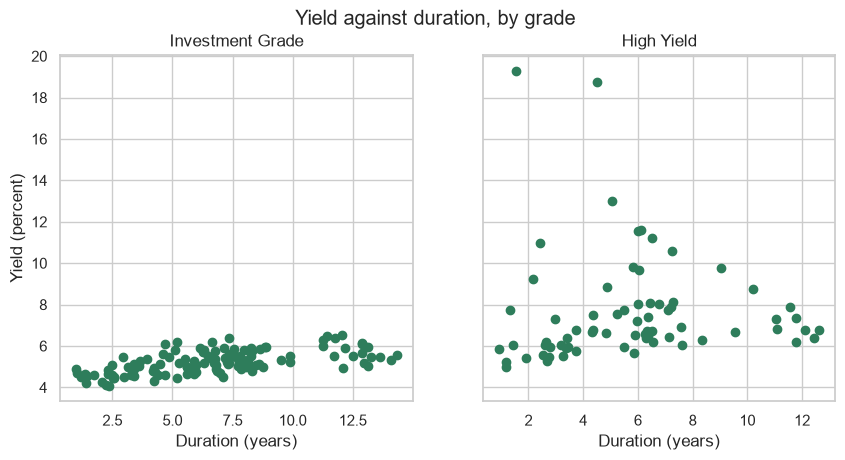

In [34]:
# two panels sharing a y axis, as in More Visualization; fig.suptitle() titles the figure
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for ax, grade in zip(axes, ['Investment Grade', 'High Yield']):
    part = book[book['grade'] == grade]
    ax.scatter(part['duration'], part['yield_pct'])
    ax.set_title(grade)
    ax.set_xlabel('Duration (years)')
axes[0].set_ylabel('Yield (percent)')
fig.suptitle('Yield against duration, by grade')
plt.show()

Two errors in 200 moved a correlation built from means; Visualization's 0.99 holds on the corrected column.
Investment grade yields rise with duration; high yield is set by credit, and the book's 0.01 describes neither grade.

### A Maturity Ladder

In [35]:
# years left, as in Combining Part 2; right=False puts exactly 3.0 years in '3 to 5'
order = ['Under 3', '3 to 5', '5 to 7', '7 to 10', '10 and over']
ladder = book.copy()
ladder['years_to_maturity'] = (ladder['maturity'] - ladder['as_of_date']).dt.days / 365.25
ladder['maturity_bucket'] = pd.cut(ladder['years_to_maturity'], bins=[0, 3, 5, 7, 10, 40],
                                   labels=order, right=False)
print('Correlation with OAS:', round(ladder['oas'].corr(ladder['years_to_maturity']), 2))
ladder.groupby('maturity_bucket', observed=True)['oas'].agg(['count', 'median'])

Correlation with OAS: 0.01


,count,median
maturity_bucket,,
Under 3,28,97.0
3 to 5,28,142.5
5 to 7,23,129.0
7 to 10,51,143.0
10 and over,70,140.5


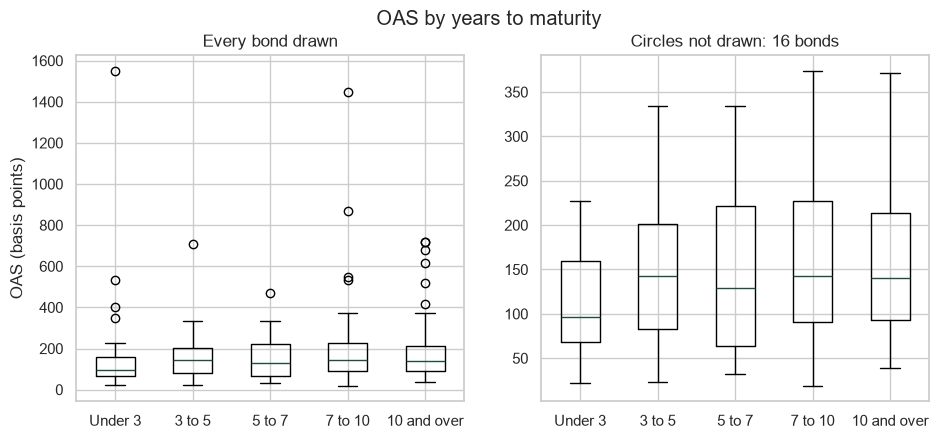

In [36]:
# one box per bucket, every bond drawn, then the same with showfliers=False
groups = [ladder.loc[ladder['maturity_bucket'] == bucket, 'oas'] for bucket in order]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].boxplot(groups, tick_labels=order)
axes[0].set_title('Every bond drawn')
axes[1].boxplot(groups, tick_labels=order, showfliers=False)
axes[1].set_title('Circles not drawn: 16 bonds')
axes[0].set_ylabel('OAS (basis points)')
fig.suptitle('OAS by years to maturity')
plt.show()

A correlation near zero, yet the median steps up after three years: a step one number misses.
`showfliers=False` leaves the circles out of the drawing, not out of the table, so the title says so.

### Duration Inside Maturity, by Bucket

`sns.relplot()` draws one scatter panel per value of `col=`; `col_order=` sets the panels' order, and `col_wrap=` starts a new row after that many.

Duration above years left: 0


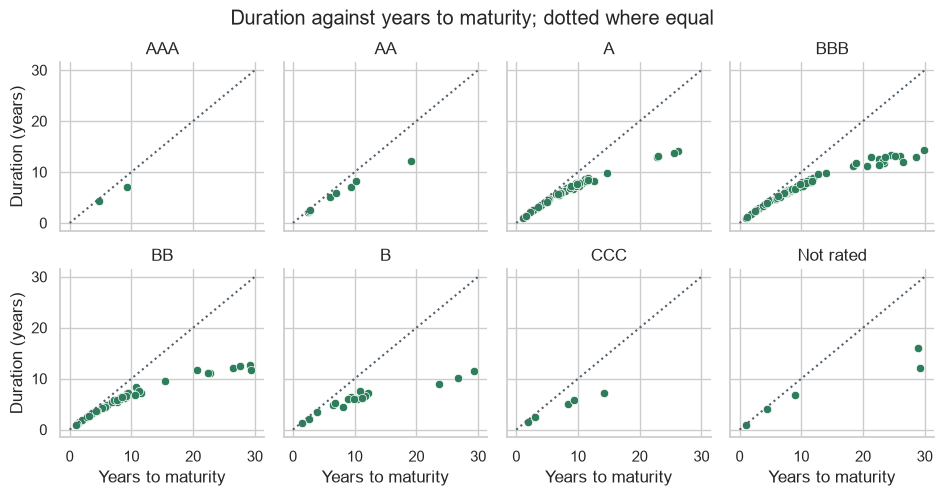

In [37]:
# no bond's duration should be longer than its years to maturity
print('Duration above years left:', (ladder['duration'] > ladder['years_to_maturity']).sum())
grid = sns.relplot(data=ladder, x='years_to_maturity', y='duration', col='bucket',
                   col_order=bucket_order, col_wrap=4, height=2.4)
for ax in grid.axes.flatten():
    ax.plot([0, 30], [0, 30], color='#52606D', linestyle=':')
grid.set_axis_labels('Years to maturity', 'Duration (years)')
grid.set_titles('{col_name}')
grid.figure.suptitle('Duration against years to maturity; dotted where equal', y=1.03)
plt.show()

Every bond sits on or under the dotted line: a two-column check, passed.

### Where the Unrated Five Sit

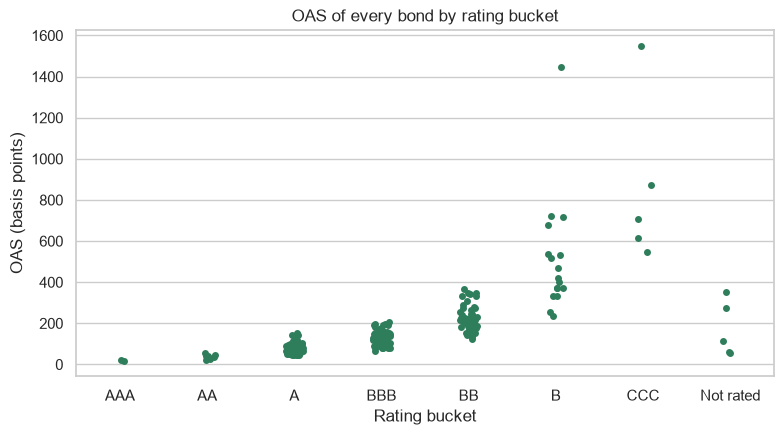

{'AAA': 21.0, 'AA': 38.5, 'A': 76.0, 'BBB': 126.5, 'BB': 217.5, 'B': 418.0, 'CCC': 707.0, 'Not rated': 113.0}


In [38]:
# stripplot(), as in More Visualization: one dot per bond, Not rated last
np.random.seed(0)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.stripplot(data=book, x='bucket', y='oas', order=bucket_order, ax=ax)
ax.set_title('OAS of every bond by rating bucket')
ax.set_xlabel('Rating bucket')
ax.set_ylabel('OAS (basis points)')
plt.show()
print(book.groupby('bucket')['oas'].median().loc[bucket_order].to_dict())

The label put the five back in the chart.
At 56 bp one sits with AA and A, at 350 bp another with BB and B: the case against one guess for all five.

**Excel side by side.** Duration in N, yield in L, grade in V:

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">Correlation</td><td align="left"><code>corr()</code></td><td align="left"><code>=CORREL(L2:L201, M2:M201)</code></td></tr>
<tr><td align="left">Within one grade</td><td align="left">a filter, then <code>corr()</code></td><td align="left"><code>=CORREL(FILTER(N2:N201, V2:V201="High Yield"), FILTER(L2:L201, V2:V201="High Yield"))</code>, Excel 2021 and 365</td></tr>
<tr><td align="left">Leave out the circles</td><td align="left"><code>showfliers=False</code></td><td align="left">Box and Whisker (Excel 2016 and later), Format Data Series, untick Show outlier points</td></tr>
</table>
<br clear="left">

`CORREL` on a filtered sheet still counts the hidden rows.

**The file is understood. Now the day in one place.**

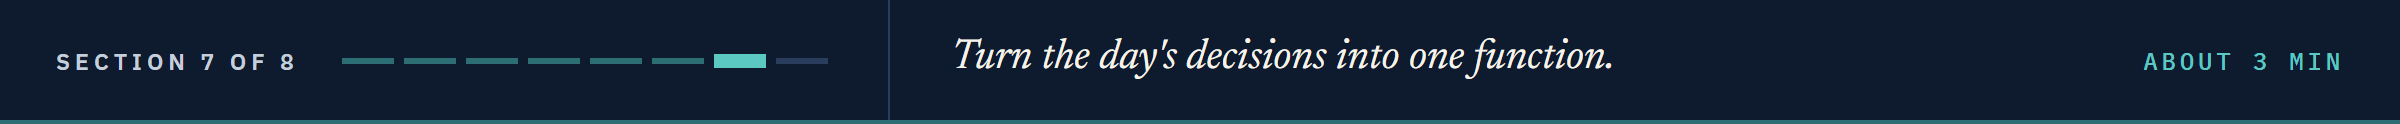

## 13.7 Make It Repeatable

### The Day in One Function

Q. Put every decision in one function, in order, so next month's file takes one line.

In [39]:
# the day's decisions in order, on a copy: neither table passed in is changed
def clean_holdings(raw, ratings):
    book = raw.copy()
    for column in ['as_of_date', 'maturity', 'price_date']:
        book[column] = pd.to_datetime(book[column], format='%Y-%m-%d', errors='coerce')
        assert book[column].notna().all(), column + ' holds a date that could not be read'
    # decision 1: remove the rows sent twice
    book = book.drop_duplicates().reset_index(drop=True)
    # decision 2: tidy the tickers
    book['ticker'] = book['ticker'].str.strip().str.upper()
    # decision 3: stale prices are flagged for ops, not changed
    # decision 4: the scale, validate= as in Combining Part 1, then a label for the unrated
    book = pd.merge(book, ratings, on='rating', how='left', validate='many_to_one')
    book['bucket'] = book['bucket'].fillna('Not rated')
    book['grade'] = book['grade'].fillna('Not rated')
    # decision 5: a yield below the IQR rule's lower limit was entered as a decimal
    q1, q3 = book['yield_pct'].quantile(0.25), book['yield_pct'].quantile(0.75)
    low = book['yield_pct'] < q1 - 1.5 * (q3 - q1)
    book.loc[low, 'yield_pct'] = (book.loc[low, 'yield_pct'] * 100).round(3)
    # decision 6: the wide bonds are real, and they stay
    return book

In [40]:
# the whole day in one line; equals() is True when two tables match in every value and type
rebuilt = clean_holdings(raw, ratings)
print(rebuilt.shape, "| same as today's book:", rebuilt.equals(book), '| raw:', raw.shape)

(200, 22) | same as today's book: True | raw: (204, 19)


### Checks That Stop

Q. Make the three control totals stop the run when they fail.

In [41]:
# assert stops the run with its message when a test fails, as on week 1's Day 3
assert len(rebuilt) == expected_bonds, f'{len(rebuilt)} rows; the note says {expected_bonds}'
assert rebuilt['par_held'].sum() == expected_face, 'face does not match the cover note'
# np.isclose() for a total with decimals, as in NumPy Part 1
assert np.isclose(rebuilt['market_value'].sum(), expected_value), 'market value is off'
print('All three control totals match the cover note.')

All three control totals match the cover note.


Q. What does the same check say about the file as received?

In [42]:
# the first check, on raw
assert len(raw) == expected_bonds, f'{len(raw)} rows; the note says {expected_bonds}'

AssertionError: 204 rows; the note says 200

Print for the reader; assert for the run nobody watches.

### The Decision Log

In [43]:
# one row per decision; every count comes from today's results, none is typed
decision_log = pd.DataFrame({
    'problem': ['Rows sent twice', 'Untidy tickers', 'Stale prices', 'No rating',
                'Yields as decimals', 'Very wide OAS'],
    'rows': [len(raw) - len(rebuilt), untidy.sum(), len(stale),
             rebuilt['rating'].isna().sum(), low_yield.sum(), wide.sum()],
    'decision': ['removed', 'tidied', 'flagged for ops', 'labelled Not rated',
                 'times 100', 'kept'],
})
decision_log

,problem,rows,decision
0,Rows sent twice,4,removed
1,Untidy tickers,8,tidied
2,Stale prices,6,flagged for ops
3,No rating,5,labelled Not rated
4,Yields as decimals,2,times 100
5,Very wide OAS,14,kept


**Next month is one line, and the log travels with the table.**

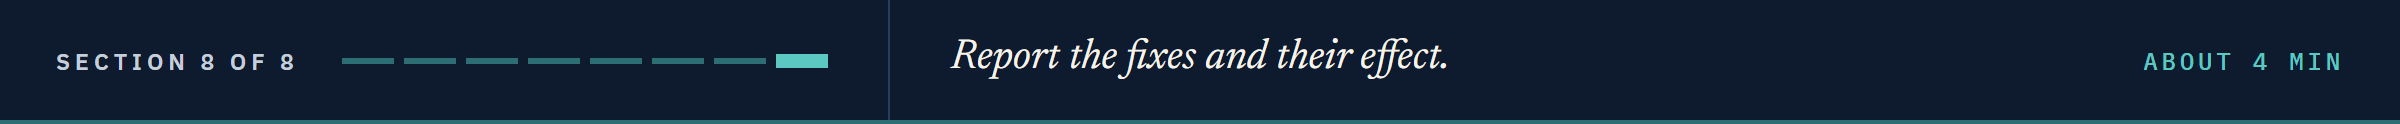

## 13.8 What the Desk Reports

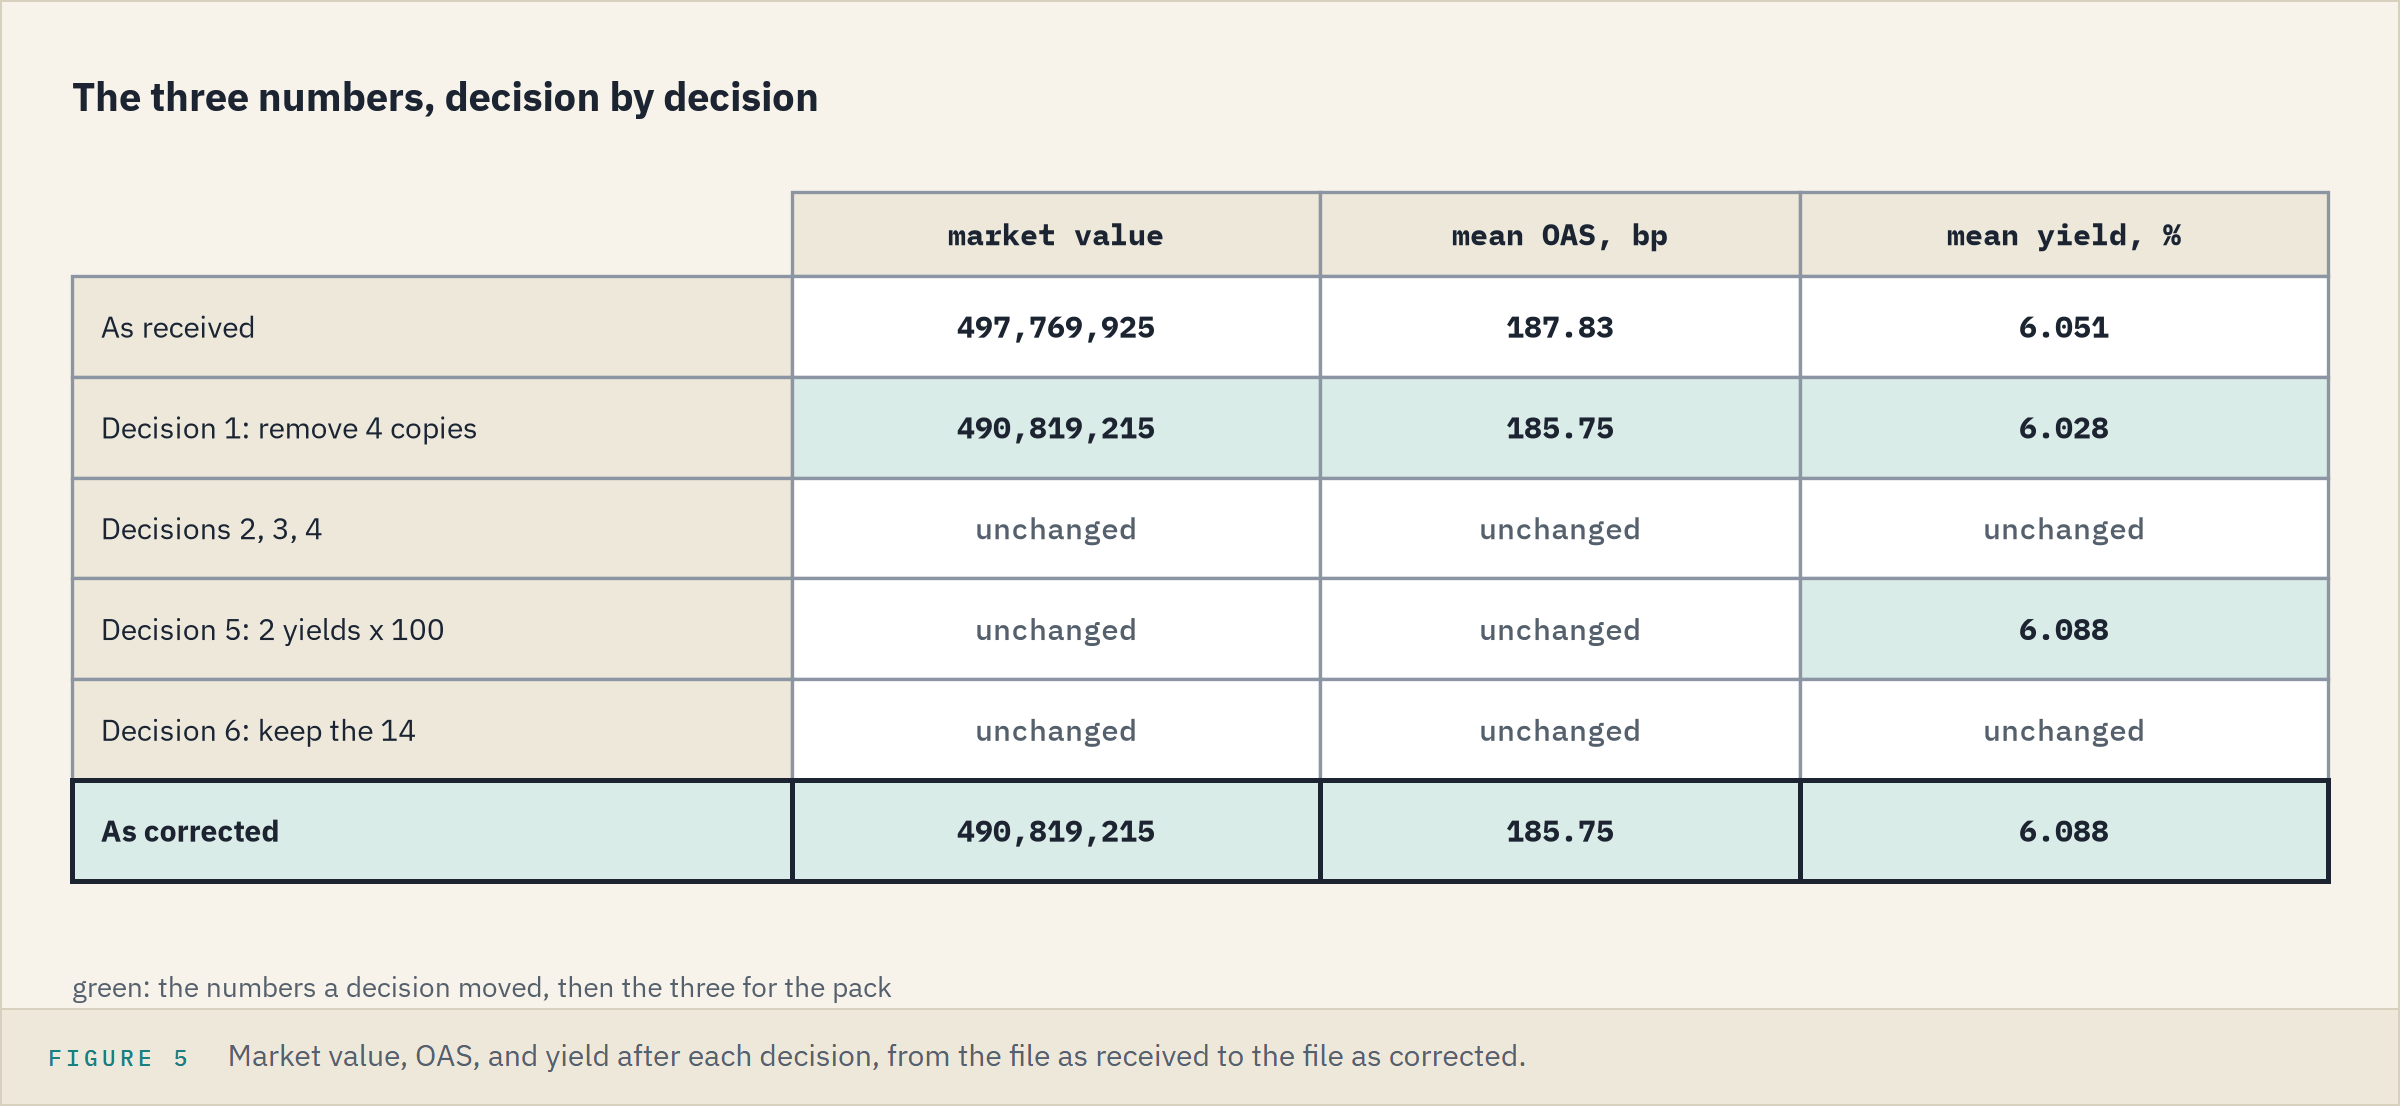

Two decisions moved the three numbers; the other four changed what they mean.

### The Test of the Day

Q. Ops has since sent `holdings.csv`, the clean book used all course. Does the corrected table match it?

In [44]:
# the clean file, dates read as dates with parse_dates=, as in Combining Part 2
dates = ['as_of_date', 'maturity', 'price_date']
clean = pd.read_csv(data_folder + 'holdings.csv', parse_dates=dates)
headline('As corrected', rebuilt)
headline('Clean file', clean)
print('Same CUSIPs, same order:', (rebuilt['cusip'] == clean['cusip']).all())
# every column of the clean file: the count of rows where the corrected table differs
for column in clean.columns:
    if (rebuilt[column] != clean[column]).sum() > 0:
        print(column, (rebuilt[column] != clean[column]).sum())

As corrected | rows: 200 | market value: 490819215.0 | OAS: 185.75 | yield: 6.088
Clean file | rows: 200 | market value: 490819215.0 | OAS: 185.75 | yield: 6.088
Same CUSIPs, same order: True
rating 5
price_date 6


The three numbers match, and 17 of 19 columns agree in every row; the two that differ are the two the day flagged.

Q. What were the five missing ratings, and was a guess of BBB- right?

In [45]:
# the clean file's ratings for the five bonds the extract left blank, with their grades
missing = rebuilt['rating'].isna()
found = pd.merge(clean.loc[missing, ['ticker', 'rating']], ratings, on='rating')
found[['ticker', 'rating', 'grade']]

,ticker,rating,grade
0,CORL,A-,Investment Grade
1,GALX,B-,High Yield
2,MORX,BB-,High Yield
3,NEVE,A-,Investment Grade
4,SYLX,A+,Investment Grade


Three investment grade, two high yield, not one BBB-: the guess would have been wrong five times out of five.

### The Report and the Workbook

For the pack: market value 490,819,215; average OAS 185.75 bp, median 135.5, the one to quote for a skewed column; average yield 6.088 percent.
For ops: four rows sent twice, eight untidy tickers, six prices from August, five ratings missing, two yields entered as decimals.

In [46]:
# the corrected table and the decision log, one sheet each, as in Combining Part 2
report_file = 'holdings_clean_2026-09-30.xlsx'
with pd.ExcelWriter(report_file) as writer:
    rebuilt.to_excel(writer, sheet_name='holdings', index=False)
    decision_log.to_excel(writer, sheet_name='decisions', index=False)
sheets = pd.read_excel(report_file, sheet_name=None)
for name, table in sheets.items():
    print(name, table.shape)
print(sheets['holdings']['market_value'].sum(), sheets['holdings']['maturity'].dtype)
os.remove(report_file)

holdings (200, 22)
decisions (6, 3)
490819215.0 datetime64[us]


**Excel side by side.** The dates open as `########` until the column is widened.

<table align="left">
<tr><th align="left">Job</th><th align="left">pandas</th><th align="left">Excel</th></tr>
<tr><td align="left">The same steps next month</td><td align="left"><code>clean_holdings(raw, ratings)</code></td><td align="left">Power Query: Applied Steps, then Refresh</td></tr>
<tr><td align="left">A control check</td><td align="left"><code>assert</code></td><td align="left"><code>=IF(COUNTA(B2:B201)=200, "ok", "CHECK")</code>, which shows and stops nothing</td></tr>
</table>
<br clear="left">

**Pack, list for ops, workbook, and next month in one line: the note is answered.**

## You Can Now

By the end of this notebook, you can:

* Check a file against its control totals before using it.
* Find dates and numbers held as text, convert them, and count what failed.
* Find repeated rows, untidy text, and values off a list.
* Leave, drop, guess, or label a gap, and say what each does to a total.
* Flag outliers with the IQR rule and z-scores, and tell an error from a real extreme.
* Package the day as a function with checks, a decision log, and a workbook.

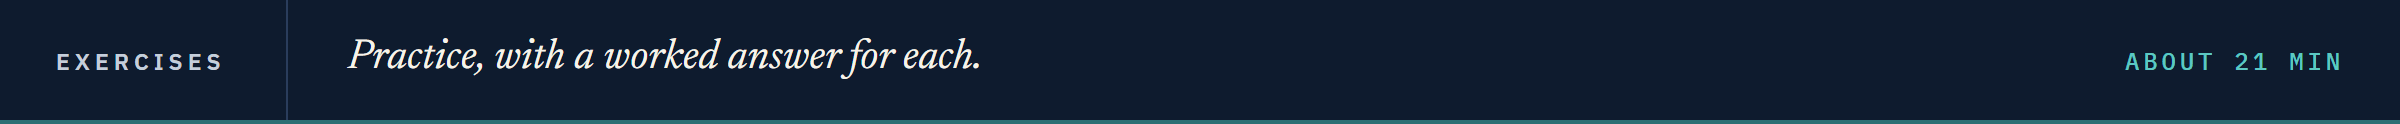

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your code, then run the check cell under it.
First run the next two cells: `check` marks answers; the loader rebuilds `book` with the lesson's `clean_holdings`.

In [47]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [48]:
# fresh copies of the two files, cleaned by the lesson's function
raw = pd.read_csv(data_folder + 'holdings_messy.csv')
ratings = pd.read_csv(data_folder + 'ratings.csv')
book = clean_holdings(raw, ratings)
print(raw.shape, book.shape, book['market_value'].sum())

(204, 19) (200, 22) 490819215.0


### Exercise 1

Q. Apply the IQR rule to `price`: store the number of bonds below the lower limit in **ex1_below** and above the upper in **ex1_above**. Do their other columns say error or real extreme?

In [49]:
ex1_below = ...
ex1_above = ...

In [50]:
check('Exercise 1 below', ex1_below, 4)
check('Exercise 1 above', ex1_above, 4)

Exercise 1 below: not attempted yet
Exercise 1 above: not attempted yet


### Exercise 2

Q. Drop the five unrated bonds with `dropna(subset=['rating'])`: which sector loses the most market value, and how much? Store them in **ex2_sector** and **ex2_lost**.

In [51]:
ex2_sector = ...
ex2_lost = ...

In [52]:
check('Exercise 2 sector', ex2_sector, 'Materials')
check('Exercise 2 lost', ex2_lost, 9532157.5)

Exercise 2 sector: not attempted yet
Exercise 2 lost: not attempted yet


### Exercise 3

Q. Store the mean and median of `dts`, to 2 places, in **ex3_mean** and **ex3_median**, and the bonds with a z-score above 3 in **ex3_count**. Draw its histogram with both marked.

In [53]:
ex3_mean = ...
ex3_median = ...
ex3_count = ...

In [54]:
check('Exercise 3 mean', ex3_mean, 1133.22)
check('Exercise 3 median', ex3_median, 811.0)
check('Exercise 3 count', ex3_count, 6)

Exercise 3 mean: not attempted yet
Exercise 3 median: not attempted yet
Exercise 3 count: not attempted yet


### Exercise 4

Q. Store the correlation of `coupon` and `price`, to 2 places, for all bonds, Investment Grade, and High Yield in **ex4_all**, **ex4_ig**, and **ex4_hy**. Draw the two grades side by side.

In [55]:
ex4_all = ...
ex4_ig = ...
ex4_hy = ...

In [56]:
check('Exercise 4 all bonds', ex4_all, 0.31)
check('Exercise 4 Investment Grade', ex4_ig, 0.81)
check('Exercise 4 High Yield', ex4_hy, 0.07)

Exercise 4 all bonds: not attempted yet
Exercise 4 Investment Grade: not attempted yet
Exercise 4 High Yield: not attempted yet


### Exercise 5

Q. Write `clean_and_flag(raw, ratings)`: call `clean_holdings`, add a column `stale_price`, True where the price date is before the as-of date, and assert with a message that no CUSIP appears twice. Store its result on `raw` in **ex5_book**.

In [57]:
def clean_and_flag(raw, ratings):
    return ...


ex5_book = clean_and_flag(raw, ratings)

In [58]:
if ex5_book is ... or ex5_book is None:
    check('Exercise 5', ex5_book, 23)
else:
    check('Exercise 5 columns', ex5_book.shape[1], 23)
    check('Exercise 5 stale prices', int(ex5_book['stale_price'].sum()), 6)
    # one CUSIP on two rows that differ: the function should stop on it
    broken = pd.concat([raw, raw.head(1).assign(par_held=1000)], ignore_index=True)
    try:
        clean_and_flag(broken, ratings)
        stopped = False
    except AssertionError as error:
        stopped = True
        print('Stopped with:', error)
    check('Exercise 5 the assert stops a repeated CUSIP', stopped, True)

Exercise 5: not attempted yet


### Exercise 6

Q. Write the lesson's fill test yourself for `yield_pct`: 100 draws of 8 blanks with `book.sample(8, random_state=seed)`. Store the average misses, to 2 places, in **ex6_all** (column median) and **ex6_bucket** (bucket median).

In [59]:
ex6_all = ...
ex6_bucket = ...

In [60]:
check('Exercise 6 column median', ex6_all, 1.07)
check('Exercise 6 bucket median', ex6_bucket, 0.64)

Exercise 6 column median: not attempted yet
Exercise 6 bucket median: not attempted yet


### Exercise 7: AI check

An AI assistant was asked to clean the extract and report bonds, market value, and mean OAS.
Its code, written for this course in an AI's style, runs and has one bug.

Q. Before you run it: what should the three numbers be? Then run it, find the bug, and fix the cell.

In [61]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
# load the extract
data = pd.read_csv(data_folder + 'holdings_messy.csv')

# remove repeated rows
data = data.drop_duplicates()

# remove incomplete rows
data = data.dropna()

ex7_bonds = len(data)
ex7_value = data['market_value'].sum()
ex7_oas = round(data['oas'].mean(), 2)
print('Bonds:', ex7_bonds, '| market value:', ex7_value, '| mean OAS:', ex7_oas)

Bonds: 195 | market value: 475476677.5 | mean OAS: 186.15


In [62]:
check('Exercise 7 bonds', ex7_bonds, 200)
check('Exercise 7 market value', ex7_value, 490819215.0)
check('Exercise 7 mean OAS', ex7_oas, 185.75)

Exercise 7 bonds: not yet. You have 195
Exercise 7 market value: not yet. You have 475476677.5
Exercise 7 mean OAS: not yet. You have 186.15


## Congratulations!

You made it through Exploratory Data Analysis.

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Can the file be trusted?</td><td align="left">After six decisions, it matches the clean file</td></tr>
<tr><td align="left">The list for ops</td><td align="left">4 copies, 8 tickers, 6 August prices, 5 ratings, 2 yields</td></tr>
<tr><td align="left">Next month</td><td align="left">one line, <code>clean_holdings(raw, ratings)</code>, checked by <code>assert</code></td></tr>
</table>
<br clear="left">

Be proud: you can say why a number can be trusted, and show the evidence.
Next, the Treasury yields case study puts the same order of work on a new kind of table: one row a day for over eleven years.

[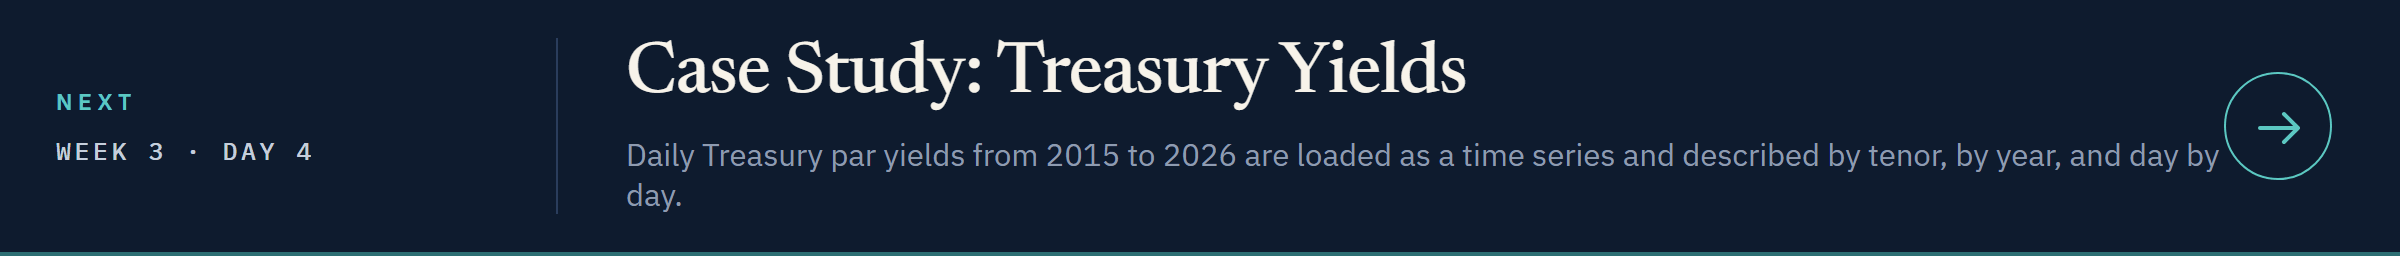](../day4/14_case_study_treasury_yields.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week3/day4/14_case_study_treasury_yields.ipynb)